# 02 — EDA và thiết kế đánh giá
**Phụ trách:** Nguyễn Đức Hưng  
**Trạng thái:** đã hoàn thành EDA phân bố, domain audit thật, Group CV thật và official feature EDA trên core train. Hai URL unresolved_domain được báo riêng và không tham gia CV/X.

**Đầu vào:** bảng chuẩn bị của Khiêm, domain đăng ký/features từ Hy.  
**Đầu ra:** EDA, kiểm tra domain/split và fold_id để Phúc chạy cùng cấu hình.

## 0. Môi trường và đường dẫn
Mặc định chạy local: cài requirements.txt trong .venv, mở notebook bằng VS Code/Jupyter và chọn kernel của .venv. Dataset ở data/ hoặc vị trí PHISHGUARD_DATA_DIR trên máy mình. Ô dưới chỉ nạp đường dẫn/config; Colab là lựa chọn thêm theo README.

In [1]:
from pathlib import Path
import os
import sys
import tomllib

start = Path(os.environ.get("PHISHGUARD_ROOT", Path.cwd())).expanduser().resolve()
candidates = (start, *start.parents)
PROJECT_ROOT = next(
    (p for p in candidates if (p / "pyproject.toml").is_file()
     and (p / "src" / "phishguard_vn").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Chuyen working directory vao repo hoac dat PHISHGUARD_ROOT "
        "toi thu muc du an tren may ban."
    )
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from phishguard_vn.paths import get_data_dir, get_config_path
DATA_DIR = get_data_dir()
with get_config_path().open("rb") as handle:
    CONFIG = tomllib.load(handle)

print("Project:", PROJECT_ROOT)
print("Dataset:", DATA_DIR)
print("Config:", CONFIG["experiment"]["name"])


Project: /Users/nguyenduchung/PhishGuardVN
Dataset: /Users/nguyenduchung/PhishGuardVN/data
Config: week4_e1_core_lr


## 1. Nhãn, tier, nguồn và split

Phân tích mô tả đối chiếu dữ liệu gốc PhishVN với tập core Gold/Silver do Khiêm chuẩn bị, đồng thời xem xét phần bronze bị loại. Mục tiêu là xác định những thay đổi về thành phần nhãn, nguồn và split có thể ảnh hưởng tới việc xây dựng và diễn giải baseline.

Các thống kê được tính từ CSV local bằng `load_dataset()` và `prepare_core()`. Tỷ lệ phân bố sử dụng tổng số URL của từng dataset; tỷ lệ lớp theo tier, source hoặc split sử dụng tổng số URL trong nhóm tương ứng. Bảng và biểu đồ trình bày trực tiếp dưới đây, không tạo thêm tệp báo cáo.

Việc kiểm kê test chỉ nhằm mô tả thành phần dữ liệu. Không thay đổi split, huấn luyện mô hình, lựa chọn features hoặc điều chỉnh threshold trong bước EDA này.

Đối chiếu hoàn tất: tổng hàng, mẫu số tỷ lệ, giá trị dữ liệu và split được bảo toàn.


/Users/nguyenduchung/PhishGuardVN/src/phishguard_vn/data.py:19: DtypeWarning: Columns (6: impersonated_org, 21: status) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


Tập core được đọc từ CSV local của Khiêm và đã đối chiếu toàn bộ giá trị theo ID.

Phân bố nhãn được so sánh giữa dữ liệu gốc, core Gold/Silver và phần bronze nhằm xác định sự thay đổi về quy mô và class imbalance. Tỷ lệ mỗi lớp dùng tổng số URL trong từng tập; tỷ số mất cân bằng bằng số mẫu lớp đa số chia cho số mẫu lớp thiểu số. Ký hiệu ∞ biểu thị tập chỉ có một lớp.

Tập dữ liệu,Tổng URL,Benign (n),Phishing (n),Benign (%),Phishing (%),Đa số/thiểu số
Dữ liệu gốc,"53,116","16,410","36,706",30.89%,69.11%,2.24
Core Gold/Silver,"18,997","16,410","2,587",86.38%,13.62%,6.34
Bronze,"34,119",0,"34,119",0.00%,100.00%,∞


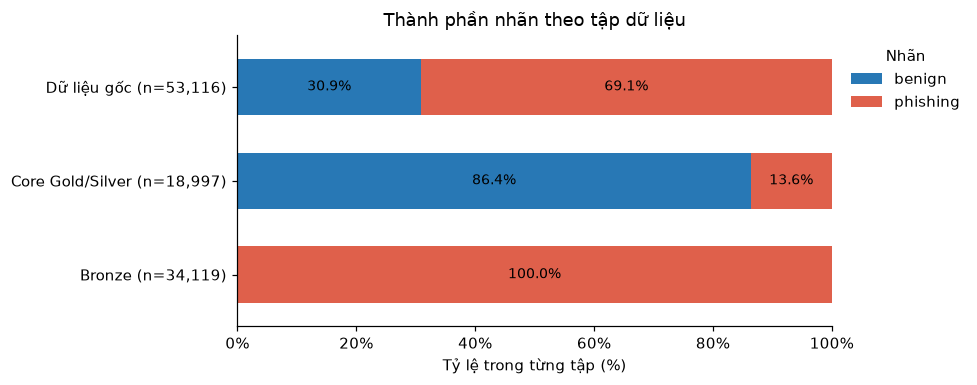

Tỷ lệ phishing giảm từ **69.11%** ở dữ liệu gốc xuống **13.62%** trong core, chênh lệch **55.49 điểm phần trăm**. Tỷ số đa số/thiểu số tăng từ **2.24** lên **6.34**, đồng thời lớp đa số đổi từ phishing sang benign. Do đó, accuracy đơn lẻ không đủ phản ánh hiệu quả với lớp phishing; kết quả baseline cần được diễn giải cùng số mẫu mỗi lớp và confusion matrix.

Phân tích theo tier xác định phần dữ liệu bị loại khi lựa chọn core. Cột Gốc (%) dùng tổng số URL của dữ liệu gốc; Benign (%) và Phishing (%) dùng tổng số URL bên trong từng tier. Hai mẫu số này lần lượt mô tả quy mô đóng góp của tier và thành phần nhãn của tier đó.

Tier,Tổng URL,Gốc (%),Benign (n),Phishing (n),Benign (%),Phishing (%)
gold,"9,593",18.06%,"7,905","1,688",82.40%,17.60%
silver,"9,404",17.70%,"8,505",899,90.44%,9.56%
bronze,"34,119",64.23%,0,"34,119",0.00%,100.00%


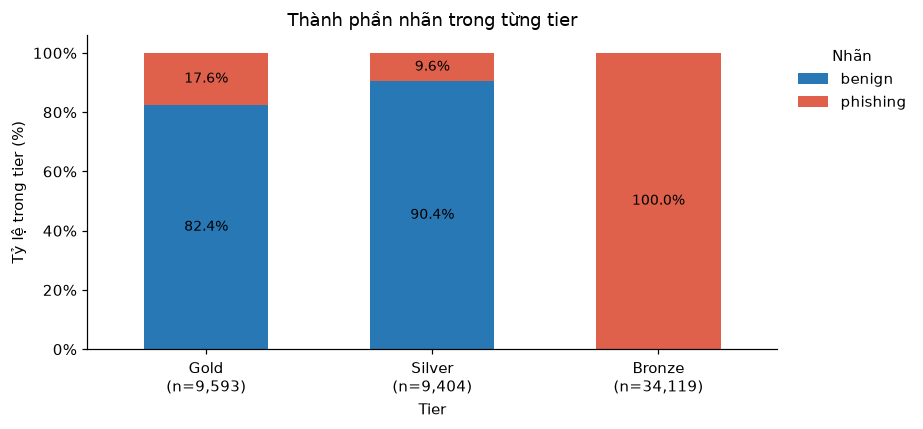

Bronze có **34,119 URL**, trong đó **34,119 phishing**. Phần này chiếm **64.23%** dữ liệu gốc. Loại bronze làm giảm riêng lớp phishing trong corpus hiện tại, trong khi toàn bộ benign được giữ lại. Gold/Silver phản ánh confidence tier theo tài liệu tác giả; việc lựa chọn hai tier này không tương đương với xác nhận độc lập rằng mọi nhãn đều chính xác.

Phân bố nguồn được đối chiếu trước và sau khi lựa chọn core để nhận diện sự thay đổi về quần thể thu thập. Gốc (%) và Core (%) có mẫu số là tổng URL của từng tập tương ứng; Phishing (%) dùng tổng URL bên trong nguồn của dữ liệu gốc. Bảng nguồn × tier bổ sung bằng chứng về cơ chế loại mẫu.

Nguồn,Tổng URL,Gốc (%),Core (n),Core (%),Phishing (%)
chongluadao,"33,823",63.68%,0,0.00%,100.00%
tranco,"5,993",11.28%,"5,993",31.55%,0.00%
tinnhiem_web,"5,879",11.07%,"5,879",30.95%,0.00%
tinnhiemmang,"2,587",4.87%,"2,587",13.62%,100.00%
tranco_vn,"2,512",4.73%,"2,512",13.22%,0.00%
tinnhiem_org,"2,026",3.81%,"2,026",10.66%,0.00%
openphish,296,0.56%,0,0.00%,100.00%


Nguồn,gold,silver,bronze
chongluadao,0,0,"33,823"
tranco,0,"5,993",0
tinnhiem_web,"5,879",0,0
tinnhiemmang,"1,688",899,0
tranco_vn,0,"2,512",0
tinnhiem_org,"2,026",0,0
openphish,0,0,296


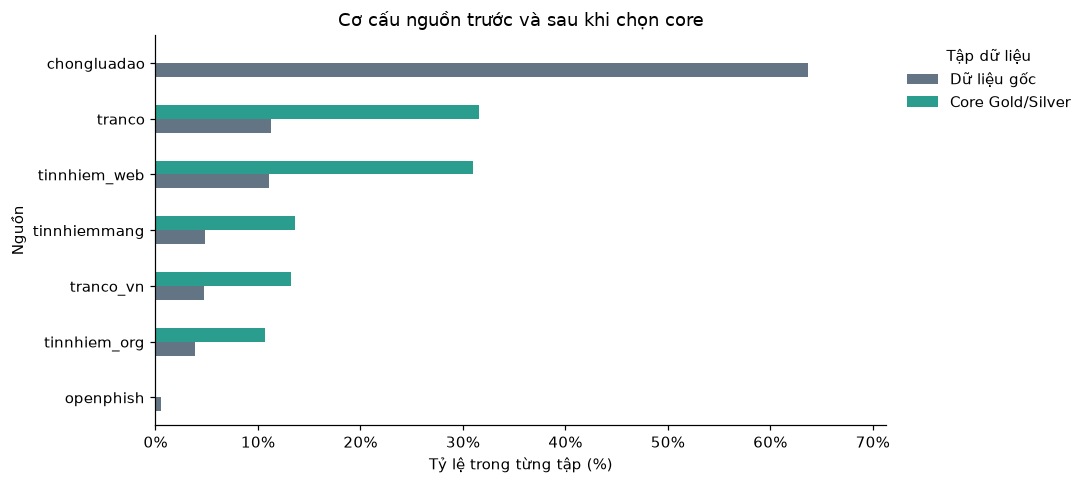

Nguồn **chongluadao** đóng góp **33,823 URL (63.68%)** trong dữ liệu gốc. Các nguồn vắng trong core là **chongluadao, openphish**; phishing trong core chỉ đến từ **tinnhiemmang**. Đồng thời, **7/7 nguồn chỉ chứa một nhãn** trong CSV. Những quan sát này cho thấy thay đổi về phạm vi nguồn và gợi ý rủi ro source-specific artifacts. Chúng chưa chứng minh data leakage hoặc đo lường ảnh hưởng lên dự đoán; cần kiểm chứng ở giai đoạn baseline và giữ metadata nguồn/tier ngoài X.

Thành phần các split hiện có được kiểm kê riêng cho dữ liệu gốc và core. Trong tập (%) là tỷ lệ URL của split trên tổng dataset tương ứng; Benign (%) và Phishing (%) dùng tổng URL của chính split. Bảng tier × split xác định các nhóm có ít hoặc không có mẫu của một lớp. Các thống kê test chỉ phục vụ mô tả, không dùng lựa chọn mô hình hoặc threshold.

Tập dữ liệu,Split,Tổng URL,Trong tập (%),Benign (n),Phishing (n),Benign (%),Phishing (%)
Core Gold/Silver,train,"13,080",68.85%,"11,004","2,076",84.13%,15.87%
Core Gold/Silver,val,"1,585",8.34%,"1,561",24,98.49%,1.51%
Core Gold/Silver,test,"4,332",22.80%,"3,845",487,88.76%,11.24%
Dữ liệu gốc,train,"36,909",69.49%,"11,004","25,905",29.81%,70.19%
Dữ liệu gốc,val,"7,266",13.68%,"1,561","5,705",21.48%,78.52%
Dữ liệu gốc,test,"8,941",16.83%,"3,845","5,096",43.00%,57.00%


Tier,Split,Tổng URL,Benign (n),Phishing (n),Phishing (%)
bronze,test,"4,609",0,"4,609",100.00%
bronze,train,"23,829",0,"23,829",100.00%
bronze,val,"5,681",0,"5,681",100.00%
gold,test,"2,673","2,604",69,2.58%
gold,train,"6,640","5,021","1,619",24.38%
gold,val,280,280,0,0.00%
silver,test,"1,659","1,241",418,25.20%
silver,train,"6,440","5,983",457,7.10%
silver,val,"1,305","1,281",24,1.84%


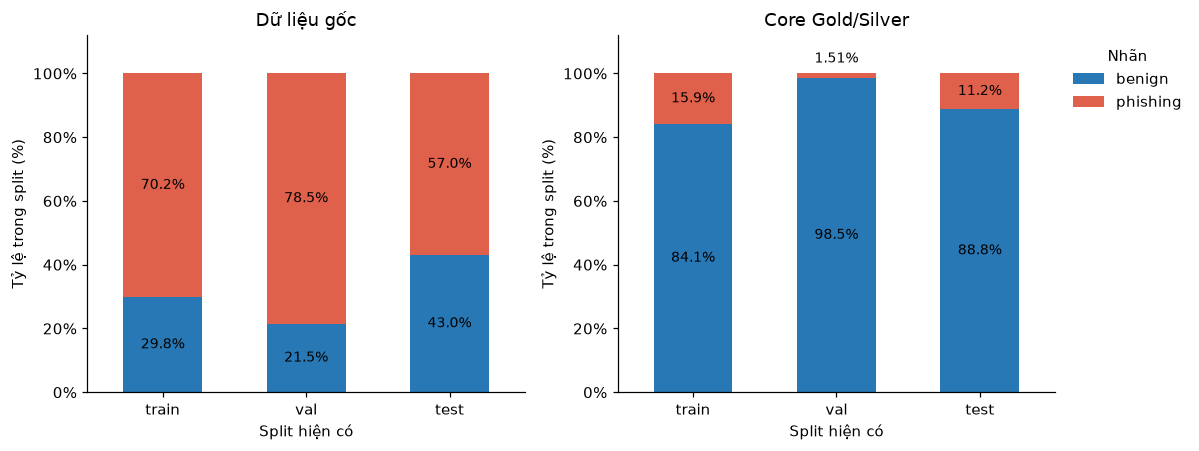

Đối chiếu theo ID cho phép phân biệt thay đổi do tiêu chí chọn core với mất mẫu do thao tác ghép bảng. Số lượng bị loại trong bảng sau bằng dữ liệu gốc trừ core ở cùng split và cùng lớp; không có thay đổi assignment.

Split,URL bị loại,Phishing bị loại,Benign bị loại
train,"23,829","23,829",0
val,"5,681","5,681",0
test,"4,609","4,609",0


Core giữ **35.77%** dữ liệu gốc; toàn bộ **34,119** bản ghi bị loại thuộc bronze. Validation giảm từ **5,705** xuống **24 phishing**, do loại **5,681** mẫu bronze, không phải do mất ID hoặc chia lại split. Tỷ lệ phishing trong core validation là **1.51%** (24/1,585); Gold validation có **0** phishing. Với số positive hiện tại, một mẫu làm recall thay đổi **4.17 điểm phần trăm**. Đây là độ phân giải của recall, không phải sai số chuẩn hoặc khoảng tin cậy.

Quan sát,Bằng chứng,Hàm ý đối với baseline,Hướng xử lý
Validation core ít positive,24/1585,Recall/PR-AUC và lựa chọn mô hình có thể thiếu ổn định.,Dùng validation bổ sung; Group CV core train được kiểm tra tại Mục 3.
Gold validation thiếu positive,phishing=0,ROC-AUC và recall positive không xác định khi chỉ có benign; PR không có ý nghĩa.,Không báo cáo Gold-only validation như đánh giá đủ hai lớp.
Source gắn chặt với label,7/7 source chỉ có một nhãn,Rủi ro source artefact; chưa chứng minh leakage.,Giữ metadata ngoài X; đánh giá giả thuyết bằng baseline và dữ liệu phù hợp.
Loại core thay đổi quần thể,"34,119 bronze bị loại",Mất phần lớn positive và thu hẹp nguồn; chưa bảo đảm generalization tốt hơn.,Báo cáo subset/số lớp rõ; không so sánh metric giữa các quần thể máy móc.


Không ghi nhận giá trị thiếu ở label, tier, source và split trong **53,116** bản ghi: **0** ô thiếu. Đây là kết quả kiểm tra mẫu số, không phải một bất thường dữ liệu. Về đánh giá, core validation có cả hai lớp nên ROC-AUC có thể tính được, nhưng ít positive làm ước lượng kém ổn định. Khi không có positive thật, recall phishing và ROC-AUC hai lớp không xác định; precision còn phụ thuộc số predicted-positive. PR-AUC cần nêu rõ định nghĩa (AP hoặc diện tích hình thang) và không diễn giải giá trị quy ước trên tập thiếu positive như bằng chứng hiệu quả. Các kết luận về hiệu quả mô hình chưa được kiểm định trong EDA này.

In [2]:
# Phần EDA của Hưng: bảng và hình hiển thị ngay trong notebook, không xuất file khác.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown, HTML
from html import escape
from phishguard_vn.data import load_dataset, prepare_core

original_df = load_dataset(DATA_DIR / CONFIG["data"]["dataset_file"])
original_fingerprint = pd.util.hash_pandas_object(original_df, index=True)
expected_core_df = prepare_core(original_df)
core_path = PROJECT_ROOT / "data" / "interim" / "core_gold_silver.csv"
if core_path.is_file():
    core_df = load_dataset(core_path)
    pd.testing.assert_frame_equal(
        core_df.set_index("id").sort_index(),
        expected_core_df.set_index("id").sort_index(), check_dtype=False,
    )
    display(Markdown("Tập core được đọc từ CSV local của Khiêm và đã đối chiếu toàn bộ giá trị theo ID."))
else:
    core_df = expected_core_df.copy()
    display(Markdown("Chưa có CSV core local; tập core được tạo trong bộ nhớ bằng hàm `prepare_core()` của Khiêm."))
bronze_df = original_df.loc[original_df["tier"].eq("bronze")].copy()
datasets = {"original": original_df, "core": core_df}
labels = ["benign", "phishing"]
colors = ["#2878b5", "#df604b"]
for name, part in {**datasets, "bronze": bronze_df}.items():
    required = {"id", "url", "label", "tier", "source", "split"}
    if not required.issubset(part.columns):
        raise ValueError(f"{name}: thiếu cột {sorted(required - set(part.columns))}")
    if part["label"].isna().any() or not set(part["label"]).issubset(labels):
        raise ValueError(f"{name}: nhãn thiếu/ngoài schema; cần kiểm tra Phase 01.")
    if part["id"].isna().any() or not part["id"].is_unique:
        raise ValueError(f"{name}: ID thiếu hoặc trùng; cần kiểm tra Phase 01.")
assert set(core_df["id"]).isdisjoint(bronze_df["id"])
assert set(core_df["id"]) | set(bronze_df["id"]) == set(original_df["id"])
assert len(original_df) == len(core_df) + len(bronze_df)
split_order = [s for s in ["train", "val", "test"] if s in original_df["split"].dropna().unique()]
split_order += sorted(set(original_df["split"].dropna()) - set(split_order))
if original_df["split"].isna().any():
    split_order.append("(missing)")

def class_counts(part, by=None):
    """Mỗi hàng là một nhóm; label % có mẫu số là total của chính nhóm đó."""
    if by:
        keys = [by] if isinstance(by, str) else by
        work = part[keys + ["label"]].copy()
        for key in keys:
            work[key] = work[key].astype("string").fillna("(missing)")
        table = work.groupby(keys + ["label"], dropna=False).size().unstack(
            "label", fill_value=0
        ).reindex(columns=labels, fill_value=0).reset_index()
    else:
        table = pd.DataFrame([part["label"].value_counts().reindex(labels, fill_value=0)])
    table.columns.name = None
    table["total"] = table[labels].sum(axis=1)
    for label in labels:
        table[f"{label}_pct"] = 100 * table[label] / table["total"].replace(0, np.nan)
    return table

def show_figure(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

# Định dạng chỉ áp dụng cho bản hiển thị, không đổi giá trị trong các bảng.
table_names = {
    "dataset": "Tập dữ liệu", "total": "Tổng URL", "tier": "Tier",
    "source": "Nguồn", "split": "Split", "benign": "Benign (n)",
    "phishing": "Phishing (n)", "benign_pct": "Benign (%)", "phishing_pct": "Phishing (%)",
    "majority_to_minority_ratio": "Đa số/thiểu số",
    "original_share_pct": "Gốc (%)", "core_n": "Core (n)", "core_share_pct": "Core (%)",
    "dataset_share_pct": "Trong tập (%)", "excluded_total": "URL bị loại",
    "excluded_phishing": "Phishing bị loại", "excluded_benign": "Benign bị loại",
    "observation": "Quan sát", "evidence": "Bằng chứng",
    "impact": "Hàm ý đối với baseline", "follow_up": "Hướng xử lý",
}
dataset_names = {"original": "Dữ liệu gốc", "core": "Core Gold/Silver", "bronze": "Bronze"}

def display_table(table, caption, columns=None):
    """Định dạng bản sao: số đếm nguyên; phần trăm và ratio có hai chữ số thập phân."""
    shown = table[columns].copy() if columns is not None else table.copy()
    if shown.index.name is not None:
        shown = shown.reset_index()
    if "dataset" in shown:
        shown["dataset"] = shown["dataset"].replace(dataset_names)
    formatters = {}
    for column in shown:
        if pd.api.types.is_numeric_dtype(shown[column]):
            if column.endswith("_pct"):
                formatters[column] = lambda value: f"{value:.2f}%"
            elif column == "majority_to_minority_ratio":
                formatters[column] = lambda value: "∞" if np.isinf(value) else f"{value:.2f}"
            else:
                formatters[column] = lambda value: f"{value:,.0f}"
    shown = shown.rename(columns=table_names)
    shown.columns.name = None
    formatters = {table_names.get(c, c): fmt for c, fmt in formatters.items()}
    content = shown.to_html(index=False, border=0, na_rep="—", formatters=formatters)
    display(HTML(f'<div style="overflow-x:auto"><p><strong>{escape(caption)}</strong></p>{content}</div>'))

def annotate_percentages(ax, horizontal=False):
    for container in ax.containers:
        values = [patch.get_width() if horizontal else patch.get_height() for patch in container]
        texts = [f"{v:.1f}%" if v >= 5 else "" for v in values]
        ax.bar_label(container, labels=texts, label_type="center", fontsize=9)
        if not horizontal:
            for patch, value in zip(container, values):
                if 0 < value < 5:
                    ax.annotate(f"{value:.2f}%",
                                (patch.get_x() + patch.get_width()/2, patch.get_y() + value),
                                xytext=(0, 5), textcoords="offset points",
                                ha="center", va="bottom", fontsize=9)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})

# 1. Nhãn: count, % trong từng tập, imbalance = số lớp đa số / số lớp thiểu số.
class_table = pd.concat([
    class_counts(part).assign(dataset=name, columns=len(part.columns))
    for name, part in {**datasets, "bronze": bronze_df}.items()
], ignore_index=True)
minimum = class_table[labels].min(axis=1)
class_table["majority_to_minority_ratio"] = (
    class_table[labels].max(axis=1) / minimum.replace(0, np.nan)
)
class_table.loc[minimum.eq(0) & class_table["total"].gt(0), "majority_to_minority_ratio"] = np.inf
class_table["retained_original_pct"] = 100 * class_table["total"] / len(original_df)
display(Markdown(
    "Phân bố nhãn được so sánh giữa dữ liệu gốc, core Gold/Silver và phần bronze nhằm xác định "
    "sự thay đổi về quy mô và class imbalance. Tỷ lệ mỗi lớp dùng tổng số URL trong từng tập; "
    "tỷ số mất cân bằng bằng số mẫu lớp đa số chia cho số mẫu lớp thiểu số. "
    "Ký hiệu ∞ biểu thị tập chỉ có một lớp."
))
display_table(class_table, "Bảng 1. Quy mô và thành phần nhãn",
              ["dataset", "total", "benign", "phishing", "benign_pct", "phishing_pct",
               "majority_to_minority_ratio"])
fig, ax = plt.subplots(figsize=(9, 3.6))
chart = class_table.set_index("dataset")[["benign_pct", "phishing_pct"]].copy()
chart.columns = labels
chart.index = [f"{dataset_names[name]} (n={int(rates_n):,})"
               for name, rates_n in zip(class_table["dataset"], class_table["total"])]
chart.plot.barh(ax=ax, stacked=True, color=colors, width=0.6)
annotate_percentages(ax, horizontal=True)
ax.invert_yaxis()
ax.set(title="Thành phần nhãn theo tập dữ liệu", xlabel="Tỷ lệ trong từng tập (%)", ylabel="")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.legend(title="Nhãn", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
show_figure(fig)
rates = class_table.set_index("dataset")
display(Markdown(
    f"Tỷ lệ phishing giảm từ **{rates.loc['original', 'phishing_pct']:.2f}%** ở dữ liệu gốc "
    f"xuống **{rates.loc['core', 'phishing_pct']:.2f}%** trong core, chênh lệch "
    f"**{rates.loc['original', 'phishing_pct'] - rates.loc['core', 'phishing_pct']:.2f} điểm phần trăm**. "
    f"Tỷ số đa số/thiểu số tăng từ **{rates.loc['original', 'majority_to_minority_ratio']:.2f}** "
    f"lên **{rates.loc['core', 'majority_to_minority_ratio']:.2f}**, đồng thời lớp đa số đổi "
    "từ phishing sang benign. Do đó, accuracy đơn lẻ không đủ phản ánh hiệu quả với lớp phishing; "
    "kết quả baseline cần được diễn giải cùng số mẫu mỗi lớp và confusion matrix."
))

# 2. Tier: % trong original khác với % nhãn bên trong từng tier.
tier_order = [t for t in ["gold", "silver", "bronze"] if t in original_df["tier"].unique()]
tier_table = class_counts(original_df, "tier").set_index("tier").reindex(tier_order)
tier_table["original_share_pct"] = 100 * tier_table["total"] / len(original_df)
tier_table["core_n"] = core_df["tier"].value_counts().reindex(tier_order, fill_value=0)
display(Markdown(
    "Phân tích theo tier xác định phần dữ liệu bị loại khi lựa chọn core. "
    "Cột Gốc (%) dùng tổng số URL của dữ liệu gốc; Benign (%) và Phishing (%) "
    "dùng tổng số URL bên trong từng tier. Hai mẫu số này lần lượt mô tả "
    "quy mô đóng góp của tier và thành phần nhãn của tier đó."
))
display_table(tier_table, "Bảng 2. Quy mô và thành phần nhãn theo tier",
              ["total", "original_share_pct", "benign", "phishing", "benign_pct", "phishing_pct"])
fig, ax = plt.subplots(figsize=(8.5, 4))
chart = tier_table[["benign_pct", "phishing_pct"]].copy()
chart.columns = labels
chart.index = [f"{tier.title()}\n(n={int(tier_table.loc[tier, 'total']):,})" for tier in chart.index]
chart.plot.bar(ax=ax, stacked=True, color=colors, rot=0, width=0.55)
annotate_percentages(ax)
ax.set(title="Thành phần nhãn trong từng tier", xlabel="Tier", ylabel="Tỷ lệ trong tier (%)")
ax.set_ylim(0, 106)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(title="Nhãn", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
show_figure(fig)
display(Markdown(
    f"Bronze có **{len(bronze_df):,} URL**, trong đó "
    f"**{int(bronze_df['label'].eq('phishing').sum()):,} phishing**. "
    f"Phần này chiếm **{100*len(bronze_df)/len(original_df):.2f}%** dữ liệu gốc. "
    "Loại bronze làm giảm riêng lớp phishing trong corpus hiện tại, trong khi toàn bộ benign được giữ lại. "
    "Gold/Silver phản ánh confidence tier theo tài liệu tác giả; việc lựa chọn hai tier này "
    "không tương đương với xác nhận độc lập rằng mọi nhãn đều chính xác."
))

# 3. Source: so sánh % trong original/core và liên hệ source-tier-label.
source_table = class_counts(original_df, "source").set_index("source").sort_values("total", ascending=False)
source_table["original_share_pct"] = 100 * source_table["total"] / len(original_df)
source_table["core_n"] = core_df["source"].fillna("(missing)").value_counts().reindex(source_table.index, fill_value=0)
source_table["core_share_pct"] = 100 * source_table["core_n"] / len(core_df)
source_tier_table = pd.crosstab(
    original_df["source"].astype("string").fillna("(missing)"),
    original_df["tier"].astype("string").fillna("(missing)"),
).reindex(index=source_table.index, columns=tier_order, fill_value=0)
display(Markdown(
    "Phân bố nguồn được đối chiếu trước và sau khi lựa chọn core để nhận diện sự thay đổi "
    "về quần thể thu thập. Gốc (%) và Core (%) có mẫu số là tổng URL của từng tập tương ứng; "
    "Phishing (%) dùng tổng URL bên trong nguồn của dữ liệu gốc. "
    "Bảng nguồn × tier bổ sung bằng chứng về cơ chế loại mẫu."
))
display_table(source_table, "Bảng 3. Cơ cấu nguồn trong dữ liệu gốc và core",
              ["total", "original_share_pct", "core_n", "core_share_pct", "phishing_pct"])
display_table(source_tier_table, "Bảng 4. Số URL theo nguồn và tier")
fig, ax = plt.subplots(figsize=(10, 4.5))
source_table[["original_share_pct", "core_share_pct"]].rename(
    columns={"original_share_pct": "Dữ liệu gốc", "core_share_pct": "Core Gold/Silver"}
).sort_values("Dữ liệu gốc").plot.barh(ax=ax, color=["#637585", "#2a9d8f"])
ax.set(title="Cơ cấu nguồn trước và sau khi chọn core",
       xlabel="Tỷ lệ trong từng tập (%)", ylabel="Nguồn")
ax.set_xlim(0, source_table[["original_share_pct", "core_share_pct"]].to_numpy().max() * 1.12)
ax.legend(title="Tập dữ liệu", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.xaxis.set_major_formatter(PercentFormatter(100))
show_figure(fig)
single_class_sources = int(source_table[labels].gt(0).sum(axis=1).eq(1).sum())
positive_core_sources = sorted(core_df.loc[core_df["label"].eq("phishing"), "source"].unique())
largest_source = source_table.index[0]
display(Markdown(
    f"Nguồn **{largest_source}** đóng góp **{int(source_table.iloc[0]['total']):,} URL "
    f"({source_table.iloc[0]['original_share_pct']:.2f}%)** trong dữ liệu gốc. "
    f"Các nguồn vắng trong core là **{', '.join(source_table.index[source_table['core_n'].eq(0)])}**; "
    f"phishing trong core chỉ đến từ **{', '.join(positive_core_sources)}**. "
    f"Đồng thời, **{single_class_sources}/{len(source_table)} nguồn chỉ chứa một nhãn** trong CSV. "
    "Những quan sát này cho thấy thay đổi về phạm vi nguồn và gợi ý rủi ro source-specific artifacts. "
    "Chúng chưa chứng minh data leakage hoặc đo lường ảnh hưởng lên dự đoán; "
    "cần kiểm chứng ở giai đoạn baseline và giữ metadata nguồn/tier ngoài X."
))

# 4. Split hiện có: giữ nguyên assignment; kiểm kê test không dùng chọn mô hình.
split_table = pd.concat([
    class_counts(part, "split").assign(dataset=name, dataset_share_pct=lambda t: 100*t["total"]/len(part))
    for name, part in datasets.items()
], ignore_index=True)
split_table["split"] = pd.Categorical(split_table["split"], categories=split_order, ordered=True)
split_table = split_table.sort_values(["dataset", "split"]).reset_index(drop=True)
tier_split_table = class_counts(original_df, ["tier", "split"])
display(Markdown(
    "Thành phần các split hiện có được kiểm kê riêng cho dữ liệu gốc và core. "
    "Trong tập (%) là tỷ lệ URL của split trên tổng dataset tương ứng; "
    "Benign (%) và Phishing (%) dùng tổng URL của chính split. "
    "Bảng tier × split xác định các nhóm có ít hoặc không có mẫu của một lớp. "
    "Các thống kê test chỉ phục vụ mô tả, không dùng lựa chọn mô hình hoặc threshold."
))
display_table(split_table, "Bảng 5. Quy mô và thành phần nhãn của các split",
              ["dataset", "split", "total", "dataset_share_pct", "benign", "phishing", "benign_pct", "phishing_pct"])
display_table(tier_split_table, "Bảng 6. Thành phần nhãn theo tier và split",
              ["tier", "split", "total", "benign", "phishing", "phishing_pct"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, name in zip(axes, datasets):
    chart = split_table.loc[split_table["dataset"].eq(name)].set_index("split").reindex(split_order)
    chart = chart[["benign_pct", "phishing_pct"]].copy()
    chart.columns = labels
    chart.plot.bar(ax=ax, stacked=True, color=colors, rot=0, width=0.55)
    annotate_percentages(ax)
    ax.set(title=dataset_names[name], xlabel="Split hiện có", ylabel="Tỷ lệ trong split (%)")
    ax.set_ylim(0, 112)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.get_legend().remove()
axes[1].legend(title="Nhãn", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
show_figure(fig)

# 5. Original-core: các ID loại ra phải trùng phần bronze.
original_split = split_table.loc[split_table["dataset"].eq("original")].set_index("split")
core_split = split_table.loc[split_table["dataset"].eq("core")].set_index("split")
excluded_df = original_df.loc[~original_df["id"].isin(core_df["id"])]
assert set(excluded_df["id"]) == set(bronze_df["id"])
removed_by_split = original_split[["total", "phishing", "benign"]] - core_split[["total", "phishing", "benign"]]
removed_by_split.columns = ["excluded_total", "excluded_phishing", "excluded_benign"]
display(Markdown(
    "Đối chiếu theo ID cho phép phân biệt thay đổi do tiêu chí chọn core với mất mẫu "
    "do thao tác ghép bảng. Số lượng bị loại trong bảng sau bằng dữ liệu gốc trừ core "
    "ở cùng split và cùng lớp; không có thay đổi assignment."
))
display_table(removed_by_split, "Bảng 7. Số URL bị loại khi chuyển từ dữ liệu gốc sang core")
validation_phishing = int(core_split.loc["val", "phishing"])
validation_total = int(core_split.loc["val", "total"])
gold_val_phishing = int(tier_split_table.loc[
    tier_split_table["tier"].eq("gold") & tier_split_table["split"].eq("val"), "phishing"
].sum())
recall_step = 100 / validation_phishing if validation_phishing else np.nan
display(Markdown(
    f"Core giữ **{len(core_df)/len(original_df)*100:.2f}%** dữ liệu gốc; "
    f"toàn bộ **{len(excluded_df):,}** bản ghi bị loại thuộc bronze. "
    f"Validation giảm từ **{int(original_split.loc['val','phishing']):,}** xuống "
    f"**{validation_phishing:,} phishing**, do loại **{int(removed_by_split.loc['val','excluded_phishing']):,}** "
    "mẫu bronze, không phải do mất ID hoặc chia lại split. "
    f"Tỷ lệ phishing trong core validation là **{100*validation_phishing/validation_total:.2f}%** "
    f"({validation_phishing:,}/{validation_total:,}); Gold validation có **{gold_val_phishing}** phishing. "
    f"Với số positive hiện tại, một mẫu làm recall thay đổi **{recall_step:.2f} điểm phần trăm**. "
    "Đây là độ phân giải của recall, không phải sai số chuẩn hoặc khoảng tin cậy."
))

# 6. Bất thường liên quan baseline; không lặp lại toàn bộ audit của Khiêm.
key_missing = original_df[["label", "tier", "source", "split"]].isna().sum()
anomalies = pd.DataFrame([
    {"observation": "Validation core ít positive", "evidence": f"{validation_phishing}/{validation_total}",
     "impact": "Recall/PR-AUC và lựa chọn mô hình có thể thiếu ổn định.",
     "follow_up": "Dùng validation bổ sung; Group CV core train được kiểm tra tại Mục 3."},
    {"observation": "Gold validation thiếu positive", "evidence": f"phishing={gold_val_phishing}",
     "impact": "ROC-AUC và recall positive không xác định khi chỉ có benign; PR không có ý nghĩa.",
     "follow_up": "Không báo cáo Gold-only validation như đánh giá đủ hai lớp."},
    {"observation": "Source gắn chặt với label", "evidence": f"{single_class_sources}/{len(source_table)} source chỉ có một nhãn",
     "impact": "Rủi ro source artefact; chưa chứng minh leakage.",
     "follow_up": "Giữ metadata ngoài X; đánh giá giả thuyết bằng baseline và dữ liệu phù hợp."},
    {"observation": "Loại core thay đổi quần thể", "evidence": f"{len(excluded_df):,} bronze bị loại",
     "impact": "Mất phần lớn positive và thu hẹp nguồn; chưa bảo đảm generalization tốt hơn.",
     "follow_up": "Báo cáo subset/số lớp rõ; không so sánh metric giữa các quần thể máy móc."},
])
display_table(anomalies, "Bảng 8. Các quan sát cần lưu ý khi xây dựng baseline")
display(Markdown(
    f"Không ghi nhận giá trị thiếu ở label, tier, source và split "
    f"trong **{len(original_df):,}** bản ghi: **{int(key_missing.sum())}** ô thiếu. "
    "Đây là kết quả kiểm tra mẫu số, không phải một bất thường dữ liệu. "
    "Về đánh giá, core validation có cả hai lớp nên ROC-AUC có thể tính được, "
    "nhưng ít positive làm ước lượng kém ổn định. Khi không có positive thật, recall phishing "
    "và ROC-AUC hai lớp không xác định; precision còn phụ thuộc số predicted-positive. "
    "PR-AUC cần nêu rõ định nghĩa (AP hoặc diện tích hình thang) và không diễn giải "
    "giá trị quy ước trên tập thiếu positive như bằng chứng hiệu quả. "
    "Các kết luận về hiệu quả mô hình chưa được kiểm định trong EDA này."
))

# Kiểm tra mẫu số và việc bảo toàn dữ liệu/split sau EDA.
pd.testing.assert_series_equal(
    pd.util.hash_pandas_object(original_df, index=True), original_fingerprint
)
for name, part in datasets.items():
    rows = split_table.loc[split_table["dataset"].eq(name)]
    assert int(rows["total"].sum()) == len(part)
    assert np.allclose(rows["benign_pct"] + rows["phishing_pct"], 100)
    assert np.isclose(rows["dataset_share_pct"].sum(), 100)
assert np.isclose(tier_table["original_share_pct"].sum(), 100)
assert np.isclose(source_table["original_share_pct"].sum(), 100)
assert np.isclose(source_table["core_share_pct"].sum(), 100)
print("Đối chiếu hoàn tất: tổng hàng, mẫu số tỷ lệ, giá trị dữ liệu và split được bảo toàn.")


## 2. Domain leakage và validation

Giữ các kiểm định sơ bộ ID/raw URL/url_norm, source × split × label và temporal metadata. Phần cuối sử dụng `03_registrable_domains.csv` được tạo bằng pipeline Hy đã merge tại `65b1054`, nối đủ core theo ID với `validate="one_to_one"`.

Audit domain báo số khóa chung, số URL bị ảnh hưởng và độ bao phủ, tách riêng các URL chưa resolve theo split/label. Không truy cập URL, không sửa official splits và không suy luận thêm grouping key. Không giao nhau ở domain đã resolve không đồng nghĩa đã kiểm tra được các URL chưa resolve hoặc mọi dạng campaign leakage.

In [3]:
from itertools import combinations
from phishguard_vn.splits import audit_domain_overlap, make_group_folds

table_names.update({
    "key": "Khóa", "pair": "Cặp split", "rows_n": "Số URL",
    "unique_id_n": "ID duy nhất", "missing_id_n": "ID thiếu", "duplicate_id_n": "ID lặp",
    "unique_a": "Khóa ở A", "unique_b": "Khóa ở B", "overlap_n": "Khóa chung",
    "overlap_a_pct": "Chung/A (%)", "overlap_b_pct": "Chung/B (%)",
    "conflict_groups_n": "Nhóm xung đột", "affected_rows_n": "URL liên quan",
    "safe_example": "Ví dụ đã vô hiệu hóa", "labels_seen": "Nhãn quan sát",
    "train_n": "Train (n)", "val_n": "Validation (n)",
    "train_pct": "Trong train (%)", "val_pct": "Trong validation (%)",
    "dimension": "Phân nhóm", "group": "Nhóm", "missing_n": "Thiếu ngày",
    "invalid_n": "Ngày không parse được", "valid_n": "Có ngày hợp lệ",
    "coverage_pct": "Bao phủ (%)", "first_date": "Ngày nhỏ nhất", "last_date": "Ngày lớn nhất",
})
audit_sets = {"original": original_df, "core": core_df}
identity_rows, overlap_rows, conflict_rows, safe_conflicts = [], [], [], []
for dataset, part in audit_sets.items():
    for split in split_order:
        block = part.loc[part["split"].eq(split)]
        identity_rows.append({
            "dataset": dataset, "split": split, "rows_n": len(block),
            "unique_id_n": int(block["id"].nunique()),
            "missing_id_n": int((block["id"].isna() | block["id"].str.strip().eq("")).sum()),
            "duplicate_id_n": int(block["id"].duplicated().sum()),
        })
    for key in ["id", "url"] + (["url_norm"] if "url_norm" in part else []):
        values = part[key]
        present = values.notna() & values.astype("string").str.strip().ne("").fillna(False)
        keys_by_split = {s: set(values.loc[present & part["split"].eq(s)]) for s in split_order}
        for left, right in combinations(split_order, 2):
            shared = keys_by_split[left] & keys_by_split[right]
            overlap_rows.append({
                "dataset": dataset, "key": key, "pair": f"{left} / {right}",
                "unique_a": len(keys_by_split[left]), "unique_b": len(keys_by_split[right]),
                "overlap_n": len(shared),
                "overlap_a_pct": 100*len(shared)/len(keys_by_split[left]) if keys_by_split[left] else np.nan,
                "overlap_b_pct": 100*len(shared)/len(keys_by_split[right]) if keys_by_split[right] else np.nan,
            })
        if key != "id":
            label_n = part.loc[present].groupby(key, dropna=False)["label"].nunique()
            conflicting = label_n.index[label_n.gt(1)]
            conflict_rows.append({
                "dataset": dataset, "key": key, "conflict_groups_n": len(conflicting),
                "affected_rows_n": int(part[key].isin(conflicting).sum()),
            })
            for value in list(conflicting)[:3]:
                group = part.loc[part[key].eq(value)]
                safe = str(value).replace("https://", "hxxps://").replace("http://", "hxxp://").replace(".", "[.]")
                safe_conflicts.append({
                    "dataset": dataset, "key": key, "safe_example": safe[:160],
                    "labels_seen": ", ".join(sorted(group["label"].unique())),
                })
identity_audit = pd.DataFrame(identity_rows)
preliminary_overlap = pd.DataFrame(overlap_rows)
url_conflicts = pd.DataFrame(conflict_rows)
display(Markdown(
    "Kiểm định sơ bộ sử dụng equality của khóa đang lưu trong CSV, không chuẩn hóa lại "
    "scheme, path hoặc query. Tỷ lệ Chung/A và Chung/B có mẫu số là số khóa duy nhất, "
    "không phải số dòng hoặc số domain. Mục tiêu là phát hiện trùng lặp trực tiếp "
    "trước khi có parser của Hy."
))
display_table(identity_audit, "Bảng 9. ID và quy mô các split")
display_table(preliminary_overlap, "Bảng 10. Overlap ID, raw URL và url_norm")
display_table(url_conflicts, "Bảng 11. Xung đột nhãn theo raw URL và url_norm")
if safe_conflicts:
    display_table(pd.DataFrame(safe_conflicts), "Ví dụ xung đột đã vô hiệu hóa liên kết")
core_overlap_n = int(preliminary_overlap.loc[preliminary_overlap["dataset"].eq("core"), "overlap_n"].sum())
conflict_n = int(url_conflicts["conflict_groups_n"].sum())
display(Markdown(
    f"Core có **{core_overlap_n}** khóa chung khi cộng các phép kiểm tra ID/URL/url_norm "
    f"giữa các cặp split; có **{conflict_n}** nhóm xung đột nhãn trong các bảng đã kiểm tra. "
    + ("Đã phát hiện overlap/xung đột; cần điều tra và không tự loại mẫu. " if core_overlap_n or conflict_n
       else "Chưa phát hiện trùng khóa trực tiếp trong phạm vi kiểm tra. ")
    + "Kết quả này không xác nhận các URL khác chuỗi là khác domain, khác chiến dịch hoặc độc lập về ngữ nghĩa."
))
for dataset, part in audit_sets.items():
    assert identity_audit.loc[identity_audit["dataset"].eq(dataset), "rows_n"].sum() == len(part)
    assert part["id"].notna().all() and part["id"].is_unique
assert set(core_df["id"]).issubset(original_df["id"])

# Chỉ metadata/label diagnostics: không đưa source vào X hoặc dùng test chọn cấu hình.
core_source_split = class_counts(core_df, ["source", "split"])
source_counts = pd.crosstab(core_df["source"], core_df["split"]).reindex(columns=split_order, fill_value=0)
source_shares = source_counts.div(source_counts.sum(axis=0), axis=1) * 100
source_comparison = pd.DataFrame({
    "train_n": source_counts["train"], "val_n": source_counts["val"],
    "train_pct": source_shares["train"], "val_pct": source_shares["val"],
})
source_label_support = pd.crosstab(core_df["source"], core_df["label"]).reindex(columns=labels, fill_value=0)
both_label_sources = int(source_label_support.gt(0).sum(axis=1).eq(2).sum())
single_label_sources_core = int(source_label_support.gt(0).sum(axis=1).eq(1).sum())
display(Markdown(
    "Để giải thích validation ít positive, số lượng lớp được phân rã theo source × split. "
    "Phishing (%) trong bảng 12 dùng tổng URL của chính source/split; bảng 13 dùng tổng "
    "URL toàn train hoặc validation. Do đó hai bảng trả lời hai câu hỏi khác nhau: "
    "nguồn chứa nhãn gì và nguồn đóng góp bao nhiêu trong mỗi split."
))
display_table(core_source_split, "Bảng 12. Source × split × label trong core",
              ["source", "split", "total", "benign", "phishing", "phishing_pct"])
display_table(source_comparison, "Bảng 13. Source composition của core train và validation")
train_positive = int(core_split.loc["train", "phishing"])
val_positive = int(core_split.loc["val", "phishing"])
display(Markdown(
    f"Core có **{both_label_sources}** nguồn chứa cả hai nhãn và **{single_label_sources_core}** nguồn single-label. "
    f"Train có **{train_positive:,} phishing/{int(core_split.loc['train','total']):,} URL** "
    f"({core_split.loc['train','phishing_pct']:.2f}%), còn validation có "
    f"**{val_positive:,}/{int(core_split.loc['val','total']):,}** ({core_split.loc['val','phishing_pct']:.2f}%). "
    "Sự khác biệt thành phần nguồn gắn với thay đổi prevalence trong corpus này. "
    "Đây là source-label confounding được quan sát từ dữ liệu, không chứng minh mô hình đã học source shortcut."
))

# Temporal metadata: chỉ parse ngày sự kiện; không tạo lại split.
temporal_rows = []
temporal_status = "pending_no_collected_at"
if "collected_at" in original_df and "collected_at" in core_df:
    for dataset, part in audit_sets.items():
        raw_dates = part["collected_at"].astype("string").str.strip()
        provided = raw_dates.notna() & raw_dates.ne("")
        dates = pd.to_datetime(raw_dates, format="%d/%m/%Y", errors="coerce").fillna(
            pd.to_datetime(raw_dates, format="%Y-%m-%d", errors="coerce")
        )
        invalid = provided & dates.isna()
        dated = part.assign(_event_date=dates, _date_missing=~provided, _date_invalid=invalid)
        for dimension in ["source", "tier", "label", "split"]:
            for category, group in dated.groupby(dimension, dropna=False):
                known = group["_event_date"].dropna()
                temporal_rows.append({
                    "dataset": dataset, "dimension": dimension,
                    "group": "(missing)" if pd.isna(category) else str(category),
                    "rows_n": len(group), "missing_n": int(group["_date_missing"].sum()),
                    "invalid_n": int(group["_date_invalid"].sum()), "valid_n": len(known),
                    "coverage_pct": 100*len(known)/len(group),
                    "first_date": known.min().strftime("%Y-%m-%d") if len(known) else "—",
                    "last_date": known.max().strftime("%Y-%m-%d") if len(known) else "—",
                })
    temporal_coverage = pd.DataFrame(temporal_rows)
    temporal_status = "completed"
    assert (temporal_coverage["missing_n"] + temporal_coverage["invalid_n"] +
            temporal_coverage["valid_n"]).eq(temporal_coverage["rows_n"]).all()
    display(Markdown(
        "Độ bao phủ ngày được thống kê riêng theo source, tier, label và split. "
        "Bao phủ (%) là số ngày parse hợp lệ trên số URL của nhóm. "
        "Missing/blank và có dữ liệu nhưng không parse được được phân biệt; "
        "các dòng thống kê theo nhiều chiều không được cộng với nhau."
    ))
    display_table(temporal_coverage, "Bảng 14. Độ bao phủ collected_at theo nhóm")
    label_dates = temporal_coverage.loc[
        temporal_coverage["dataset"].eq("core") & temporal_coverage["dimension"].eq("label")
    ].set_index("group")
    invalid_dates_n = int(temporal_coverage.loc[
        temporal_coverage["dataset"].eq("original") &
        temporal_coverage["dimension"].eq("source"), "invalid_n"
    ].sum())
    display(Markdown(
        f"Có **{invalid_dates_n}** ngày không parse được trong dữ liệu gốc. "
        f"Core phishing có ngày hợp lệ ở **{label_dates.loc['phishing','coverage_pct']:.2f}%** URL, "
        f"core benign ở **{label_dates.loc['benign','coverage_pct']:.2f}%**. "
        "Missingness vì vậy phụ thuộc quần thể nguồn/nhãn, không nên loại hàng hoặc thay ngày thiếu bằng scraped_at. "
        "Một số benign tinnhiem_org có collected_at trong CSV dù mô tả chung nói whitelist thường undated. "
        "Phạm vi ngày giao nhau chưa đủ kết luận temporal split sai; cần mapping domain và quy tắc split của tác giả."
    ))
else:
    display(Markdown("Temporal diagnostics đang chờ: không có collected_at ở dữ liệu đầu vào."))
pd.testing.assert_series_equal(pd.util.hash_pandas_object(original_df, index=True), original_fingerprint)
display(Markdown(
    f"**Trạng thái:** audit sơ bộ ID/URL và source/split đã chạy; temporal metadata: {temporal_status}. "
    "phần dưới tiếp tục audit mapping đã bàn giao của Hy. Các bước này không thay đổi dữ liệu hoặc split."
))

# Domain mapping từ pipeline Hy đã merge; không suy luận lại domain.
HY_HANDOFF_COMMIT = "65b1054bbc014bb2e434d722acb12073608220b4"
domain_path = PROJECT_ROOT / "data/interim/03_registrable_domains.csv"
if not domain_path.is_file():
    raise FileNotFoundError("Chạy pipeline notebook 03 tại commit 65b1054 để tạo domain mapping trước.")
domain_mapping = pd.read_csv(domain_path, dtype={"id": "string", "registrable_domain": "string"})
assert {"id", "registrable_domain", "error_reason"}.issubset(domain_mapping.columns)
assert domain_mapping["id"].notna().all() and domain_mapping["id"].is_unique
assert set(domain_mapping["id"]) == set(core_df["id"]), "Mapping phải phủ đúng toàn bộ core IDs."
core_with_domains = core_df.merge(domain_mapping, on="id", how="left", validate="one_to_one", indicator=True)
assert core_with_domains["_merge"].eq("both").all()
core_with_domains = core_with_domains.drop(columns="_merge")
real_domain_audit = audit_domain_overlap(core_with_domains)
unknown_domain_mask = core_with_domains["registrable_domain"].isna() | core_with_domains["registrable_domain"].str.strip().eq("").fillna(False)
unresolved_rows = core_with_domains.loc[unknown_domain_mask].copy()
if real_domain_audit["unknown_domain_rows"] != len(unresolved_rows):
    raise ValueError("Ngoài domain thiếu còn có grouping key không hợp lệ; cần kiểm tra policy, không tự sửa khóa.")
assert unresolved_rows["error_reason"].notna().all()
domain_overlap_rows, domain_examples = [], []
for pair in real_domain_audit["pairwise"]:
    left, right = pair["split_a"], pair["split_b"]
    shared = pair["overlap_groups"]
    affected = core_with_domains.loc[
        core_with_domains["split"].isin([left, right]) &
        core_with_domains["registrable_domain"].isin(shared)
    ]
    domain_overlap_rows.append({
        "pair": f"{left} / {right}", "unique_a": pair["groups_a"], "unique_b": pair["groups_b"],
        "overlap_n": pair["overlap_count"],
        "affected_a": int(affected["split"].eq(left).sum()),
        "affected_b": int(affected["split"].eq(right).sum()),
        "affected_total": len(affected),
    })
    for domain in shared[:3]:
        domain_examples.append({"pair": f"{left} / {right}", "safe_example": domain.replace(".", "[.]")})
real_domain_pairs = pd.DataFrame(domain_overlap_rows)
domain_coverage = core_with_domains.assign(_unknown=unknown_domain_mask).groupby(
    ["split", "label"], dropna=False
).agg(total=("id", "size"), unknown_n=("_unknown", "sum")).reset_index()
domain_coverage["unknown_pct"] = 100*domain_coverage["unknown_n"]/domain_coverage["total"]
safe_unresolved = unresolved_rows[["id", "url", "split", "label", "error_reason"]].copy()
safe_unresolved["url"] = safe_unresolved["url"].str.replace("https://", "hxxps://", regex=False).str.replace(
    "http://", "hxxp://", regex=False
).str.replace(".", "[.]", regex=False)
table_names.update({
    "affected_a": "URL ảnh hưởng A", "affected_b": "URL ảnh hưởng B",
    "affected_total": "Tổng URL ảnh hưởng", "unknown_n": "Domain chưa resolve",
    "unknown_pct": "Chưa resolve (%)", "id": "ID", "url": "URL đã vô hiệu hóa",
    "error_reason": "Lý do parser",
})
display(Markdown(
    f"**Domain audit thật.** Mapping pipeline Hy tại commit `{HY_HANDOFF_COMMIT[:7]}` phủ "
    f"**{len(core_with_domains):,} core IDs**. Handoff dùng tldextract 5.4.0, "
    "PSL snapshot đóng gói, private suffix=False. Các CSV được tạo bằng nguyên pipeline "
    "của commit đã merge; không suy luận lại domain hoặc sửa parser/features trong notebook 02."
))
display_table(real_domain_pairs, "Bảng 14a. Overlap domain đã resolve giữa các official split")
display_table(domain_coverage, "Bảng 14b. Domain chưa resolve theo split và nhãn")
display_table(safe_unresolved, "Bảng 14c. Những URL chưa resolve; không truy cập liên kết")
if domain_examples:
    display_table(pd.DataFrame(domain_examples), "Ví dụ domain giao nhau đã vô hiệu hóa")
real_domain_status = "audited_resolved_domains_unresolved_reported"
display(Markdown(
    f"Có **{int(real_domain_pairs['overlap_n'].sum())}** domain chung và "
    f"**{int(real_domain_pairs['affected_total'].sum())}** URL ảnh hưởng khi cộng ba cặp split. "
    f"Độ bao phủ domain hợp lệ là **{real_domain_audit['valid_domain_rows']:,}/"
    f"{real_domain_audit['n_rows']:,}**; **{len(unresolved_rows)}** URL chưa resolve được báo riêng. "
    "Kết luận không giao domain chỉ áp dụng các khóa đã resolve; không gán cùng một nhóm cho missing "
    "và không tự thay đổi official split hoặc xóa URL khỏi dataset."
))


Kiểm định sơ bộ sử dụng equality của khóa đang lưu trong CSV, không chuẩn hóa lại scheme, path hoặc query. Tỷ lệ Chung/A và Chung/B có mẫu số là số khóa duy nhất, không phải số dòng hoặc số domain. Mục tiêu là phát hiện trùng lặp trực tiếp trước khi có parser của Hy.

Tập dữ liệu,Split,Số URL,ID duy nhất,ID thiếu,ID lặp
Dữ liệu gốc,train,"36,909","36,909",0,0
Dữ liệu gốc,val,"7,266","7,266",0,0
Dữ liệu gốc,test,"8,941","8,941",0,0
Core Gold/Silver,train,"13,080","13,080",0,0
Core Gold/Silver,val,"1,585","1,585",0,0
Core Gold/Silver,test,"4,332","4,332",0,0


Tập dữ liệu,Khóa,Cặp split,Khóa ở A,Khóa ở B,Khóa chung,Chung/A (%),Chung/B (%)
Dữ liệu gốc,id,train / val,"36,909","7,266",0,0.00%,0.00%
Dữ liệu gốc,id,train / test,"36,909","8,941",0,0.00%,0.00%
Dữ liệu gốc,id,val / test,"7,266","8,941",0,0.00%,0.00%
Dữ liệu gốc,url,train / val,"36,909","7,266",0,0.00%,0.00%
Dữ liệu gốc,url,train / test,"36,909","8,941",0,0.00%,0.00%
Dữ liệu gốc,url,val / test,"7,266","8,941",0,0.00%,0.00%
Dữ liệu gốc,url_norm,train / val,"36,909","7,266",0,0.00%,0.00%
Dữ liệu gốc,url_norm,train / test,"36,909","8,941",0,0.00%,0.00%
Dữ liệu gốc,url_norm,val / test,"7,266","8,941",0,0.00%,0.00%
Core Gold/Silver,id,train / val,"13,080","1,585",0,0.00%,0.00%


Tập dữ liệu,Khóa,Nhóm xung đột,URL liên quan
Dữ liệu gốc,url,0,0
Dữ liệu gốc,url_norm,0,0
Core Gold/Silver,url,0,0
Core Gold/Silver,url_norm,0,0


Core có **0** khóa chung khi cộng các phép kiểm tra ID/URL/url_norm giữa các cặp split; có **0** nhóm xung đột nhãn trong các bảng đã kiểm tra. Chưa phát hiện trùng khóa trực tiếp trong phạm vi kiểm tra. Kết quả này không xác nhận các URL khác chuỗi là khác domain, khác chiến dịch hoặc độc lập về ngữ nghĩa.

...

**Domain audit thật.** Mapping pipeline Hy tại commit `65b1054` phủ **18,997 core IDs**. Handoff dùng tldextract 5.4.0, PSL snapshot đóng gói, private suffix=False. Các CSV được tạo bằng nguyên pipeline của commit đã merge; không suy luận lại domain hoặc sửa parser/features trong notebook 02.

Cặp split,Khóa ở A,Khóa ở B,Khóa chung,URL ảnh hưởng A,URL ảnh hưởng B,Tổng URL ảnh hưởng
train / val,"8,835","1,486",0,0,0,0
train / test,"8,835","1,956",0,0,0,0
val / test,"1,486","1,956",0,0,0,0


Split,label,Tổng URL,Domain chưa resolve,Chưa resolve (%)
test,benign,"3,845",0,0.00%
test,phishing,487,0,0.00%
train,benign,"11,004",0,0.00%
train,phishing,"2,076",2,0.10%
val,benign,"1,561",0,0.00%
val,phishing,24,0,0.00%


ID,URL đã vô hiệu hóa,Split,label,Lý do parser
74648118-c397-5d04-ab64-9c2973953892,vpbank[.]com[.]vn-uz[.]infor,train,phishing,unresolved_domain
27984223-c2e3-5068-a777-02f4becd0d10,techcombank[.]com-ut[.]xvz,train,phishing,unresolved_domain


Có **0** domain chung và **0** URL ảnh hưởng khi cộng ba cặp split. Độ bao phủ domain hợp lệ là **18,995/18,997**; **2** URL chưa resolve được báo riêng. Kết luận không giao domain chỉ áp dụng các khóa đã resolve; không gán cùng một nhóm cho missing và không tự thay đổi official split hoặc xóa URL khỏi dataset.

## 3. Thiết kế CV theo domain trên train

Phần này chạy **Group CV trên dữ liệu thật**, bằng API đã được kiểm thử synthetic, với `n_splits=3, seed=42`. Chỉ lấy Gold/Silver official train; grouping key phải hợp lệ theo policy hiện tại. URL chưa resolve được giữ nguyên trong dataset nhưng loại khỏi phạm vi CV có giải thích rõ bằng ID/lý do.

Kiểm tra một ID chỉ thuộc một fold, mọi nhóm domain nằm trọn trong một fold, train complement và validation không giao domain, đủ cả hai lớp ở từng phía và mapping tái lập theo seed. Xuất đúng `id,fold_id` tại `data/interim/02_group_folds_train.csv`; không ghi đè một file đã có nếu kết quả khác. Group CV không phải temporal holdout; không đổi seed/nhãn để tối ưu cân bằng.

In [4]:
# REAL DATA — synthetic cases vẫn được giữ trong tests/test_splits.py.
official_core_train = core_with_domains.loc[core_with_domains["split"].eq("train")].copy()
cv_excluded_train = official_core_train.loc[
    official_core_train["registrable_domain"].isna() |
    official_core_train["registrable_domain"].str.strip().eq("").fillna(False)
].copy()
eligible_train = official_core_train.loc[~official_core_train["id"].isin(cv_excluded_train["id"])].copy()
assert len(official_core_train) == len(eligible_train) + len(cv_excluded_train)
real_folds = make_group_folds(
    eligible_train, n_splits=CONFIG["evaluation"]["n_splits"], seed=CONFIG["experiment"]["seed"]
)
cv_joined = eligible_train.merge(real_folds, on="id", validate="one_to_one", how="left")
assert len(cv_joined) == len(eligible_train) and cv_joined["fold_id"].notna().all()
assert set(real_folds["id"]) == set(eligible_train["id"])
assert not set(real_folds["id"]) & set(core_with_domains.loc[core_with_domains["split"].ne("train"), "id"])
assert cv_joined.groupby("registrable_domain")["fold_id"].nunique().eq(1).all()
for fold_id in range(CONFIG["evaluation"]["n_splits"]):
    validation = cv_joined.loc[cv_joined["fold_id"].eq(fold_id)]
    training = cv_joined.loc[cv_joined["fold_id"].ne(fold_id)]
    assert set(validation["label"]) == set(training["label"]) == set(labels)
    assert set(validation["registrable_domain"]).isdisjoint(training["registrable_domain"])
pd.testing.assert_frame_equal(
    real_folds,
    make_group_folds(eligible_train.sample(frac=1, random_state=7),
                     n_splits=CONFIG["evaluation"]["n_splits"], seed=CONFIG["experiment"]["seed"]),
)
table_names.update({
    "fold_id": "Fold", "n_validation": "Validation (n)", "n_train": "Train (n)",
    "validation_groups": "Domain validation", "train_groups": "Domain train",
})
real_fold_summary = pd.DataFrame(real_folds.attrs["fold_summary"])
real_fold_summary["phishing_pct"] = 100*real_fold_summary["phishing_ratio"]
display(Markdown(
    f"Từ **{len(official_core_train):,} official core train URL**, "
    f"**{len(eligible_train):,}** URL đủ điều kiện và **{len(cv_excluded_train)}** bị loại khỏi CV "
    f"do **{', '.join(sorted(cv_excluded_train['error_reason'].dropna().unique()))}** "
    "(ID và nhãn đã nêu ở bảng 14c). Đây là phạm vi CV, không phải sửa dữ liệu gốc. "
    "Phishing (%) ở bảng sau dùng số URL của validation fold tương ứng."
))
display_table(real_fold_summary, "Bảng 15. Group CV thật trên official core train",
              ["fold_id", "n_validation", "validation_groups", "benign", "phishing", "phishing_pct", "n_train", "train_groups"])
prevalence_spread_pp = real_fold_summary["phishing_pct"].max() - real_fold_summary["phishing_pct"].min()
display(Markdown(
    f"Chênh lệch quy mô lớn nhất giữa các fold là "
    f"**{int(real_fold_summary['n_validation'].max()-real_fold_summary['n_validation'].min())} URL**, "
    f"và chênh lệch prevalence là **{prevalence_spread_pp:.4f} điểm phần trăm**. "
    "Đây là kết quả của seed 42 và grouping policy hiện tại, không phải kết quả tuning hoặc bảo đảm cho dataset khác."
))
fold_path = PROJECT_ROOT / "data/interim/02_group_folds_train.csv"
fold_export = real_folds[["id", "fold_id"]].copy()
fold_export.attrs = {}
if fold_path.is_file():
    saved_folds = pd.read_csv(fold_path, dtype={"id": "string"})
    assert list(saved_folds.columns) == ["id", "fold_id"]
    pd.testing.assert_frame_equal(saved_folds, fold_export, check_dtype=False)
else:
    fold_export.to_csv(fold_path, index=False)
real_cv_status = "completed_and_exported"
display(Markdown(
    f"Đã xác minh tái lập và bàn giao `{fold_path.relative_to(PROJECT_ROOT)}`: "
    f"**{len(fold_export):,} ID train**, schema chính xác `id,fold_id`, fold đánh số từ 0. "
    "Không có official val/test trong file. Unit tests synthetic và integration được chạy riêng."
))


Từ **13,080 official core train URL**, **13,078** URL đủ điều kiện và **2** bị loại khỏi CV do **unresolved_domain** (ID và nhãn đã nêu ở bảng 14c). Đây là phạm vi CV, không phải sửa dữ liệu gốc. Phishing (%) ở bảng sau dùng số URL của validation fold tương ứng.

Fold,Validation (n),Domain validation,Benign (n),Phishing (n),Phishing (%),Train (n),Domain train
0,"4,359","2,938","3,668",691,15.85%,"8,719","5,897"
1,"4,359","2,947","3,668",691,15.85%,"8,719","5,888"
2,"4,360","2,950","3,668",692,15.87%,"8,718","5,885"


Chênh lệch quy mô lớn nhất giữa các fold là **1 URL**, và chênh lệch prevalence là **0.0193 điểm phần trăm**. Đây là kết quả của seed 42 và grouping policy hiện tại, không phải kết quả tuning hoặc bảo đảm cho dataset khác.

Đã xác minh tái lập và bàn giao `data/interim/02_group_folds_train.csv`: **13,078 ID train**, schema chính xác `id,fold_id`, fold đánh số từ 0. Không có official val/test trong file. Unit tests synthetic và integration được chạy riêng.

## 4. EDA cấu trúc URL và features trên train

Giữ nguyên **Preliminary Feature EDA** từ các cột có sẵn của PhishVN. Phần bổ sung phía dưới dùng độc lập **12 numerical features official X của Hy** tại commit `65b1054`, đối chiếu feature dictionary và chỉ nối với metadata **core official train** theo ID.

Official EDA kiểm tra dtype/missing/Inf/constant, quantile theo lớp, phân bố dom_len/entropy, Spearman và IQR diagnostics. X được giữ nguyên đủ cột; không lấy nhãn val/test để chọn feature, không fit scaler/selector, không cap/xóa outlier. Các mối liên hệ quan sát vẫn cần diễn giải trong giới hạn source-label confounding.

Phân tích dưới đây chỉ dùng **13,080 core train URL**, trong đó **2,076 phishing**. Bảng kiểm kê phân biệt cột hằng, thiếu dữ liệu và giá trị không hợp lệ; dtype/miền giá trị hợp lệ chưa đồng nghĩa công thức feature đã được nghiệm thu.

Feature có sẵn,Dtype,Thiếu (n),Không hợp lệ (n),Inf,Giá trị duy nhất,Trạng thái
url_len,float64,0,0,0,52,có thể mô tả
num_dots,float64,0,0,0,6,có thể mô tả
num_subdomains,float64,0,0,0,6,có thể mô tả
has_ip,float64,0,0,0,1,constant; chỉ mô tả
has_at,float64,0,0,0,2,có thể mô tả
suspicious_tld,float64,0,0,0,2,có thể mô tả
tld,str,0,—,—,269,categorical; chưa thẩm định công thức parser


Feature có sẵn,Nhãn,Số quan sát hợp lệ,Q25,Median,Q75,Q95
url_len,benign,"11,004",11.00,16.00,27.00,34.00
url_len,phishing,"2,076",11.00,13.00,18.00,24.00
num_dots,benign,"11,004",1.00,2.00,3.00,4.00
num_dots,phishing,"2,076",1.00,1.00,2.00,2.00
num_subdomains,benign,"11,004",0.00,0.00,1.00,2.00
num_subdomains,phishing,"2,076",0.00,0.00,1.00,1.00


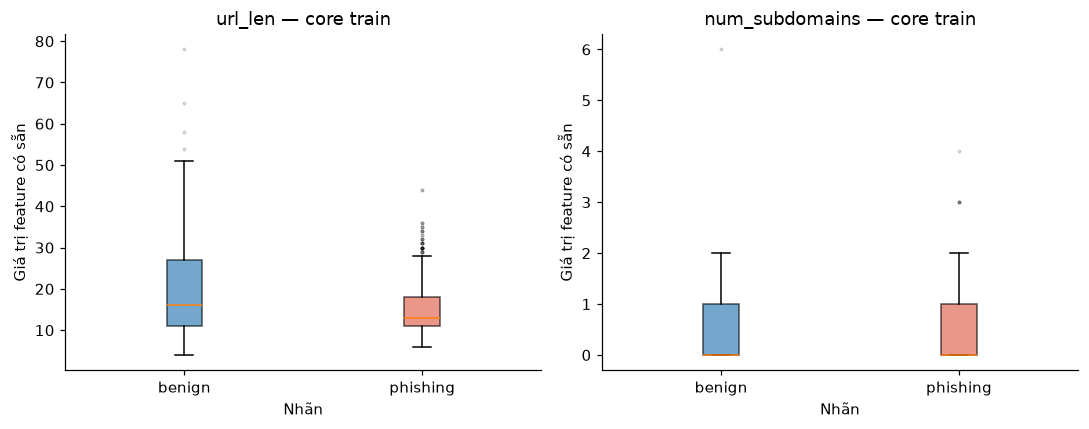

Feature có sẵn,Nhãn,Số quan sát hợp lệ,Giá trị 0,Giá trị 1,Giá trị 1 (%)
has_ip,benign,"11,004","11,004",0,0.00%
has_ip,phishing,"2,076","2,076",0,0.00%
has_at,benign,"11,004","11,001",3,0.03%
has_at,phishing,"2,076","2,076",0,0.00%
suspicious_tld,benign,"11,004","10,874",130,1.18%
suspicious_tld,phishing,"2,076","1,537",539,25.96%


Feature có sẵn,url_len,num_dots,num_subdomains
url_len,1.000,0.761,0.752
num_dots,0.761,1.000,0.899
num_subdomains,0.752,0.899,1.000


Tương quan mô tả mức đồng biến trong representation có sẵn; không chứng minh nhân quả hoặc đủ để quyết định loại feature. Nếu có selector học từ dữ liệu, bước đó phải nằm trong từng CV fold.

Feature có sẵn,Ngưỡng IQR dưới,Ngưỡng IQR trên,Ngoài ngưỡng (n),Ngoài ngưỡng (%)
url_len,-10.00,46.00,22,0.17%
num_dots,-2.00,6.00,1,0.01%
num_subdomains,-1.50,2.50,6,0.05%


Các ngưỡng IQR chỉ dùng mô tả trên train; điểm ngoài ngưỡng vẫn được giữ nguyên và không được coi mặc định là lỗi hoặc phishing. Whisker của boxplot dùng IQR riêng từng lớp; bảng 20 dùng IQR gộp toàn core train, nên hai cách đếm điểm ngoài ngưỡng không đồng nhất. Không cap, winsorize hoặc impute trong EDA.

...

**Trạng thái:** feature EDA sơ bộ core train: completed; phần official X được bổ sung độc lập ngay dưới; không dùng label val/test cho feature selection.

**Official X của Hy.** Handoff có **18,995 URL**, **12 numerical features**; phép phân tích liên quan nhãn dưới đây chỉ dùng **13,078 core train URL**. Schema/thứ tự được đối chiếu với `reports/templates/feature_dictionary.csv`, gồm đúng các cột quyết định `keep`. Các train_check của dictionary còn ghi chưa đo hoặc thống kê toàn official train có bronze; không đồng nhất chúng với kết quả core train ở đây, và không sửa dictionary của Hy.

Feature có sẵn,Dtype,Thiếu (n),Inf,Giá trị duy nhất,Khác 0 (n),Hằng trên train,Dictionary
url_len,float64,0,0,46,"13,078",Không,keep
dom_len,float64,0,0,36,"13,078",Không,keep
is_ip,float64,0,0,1,0,Có,keep
subdom_cnt,float64,0,0,6,"4,624",Không,keep
letter_cnt,float64,0,0,43,"13,078",Không,keep
digit_cnt,float64,0,0,12,"1,207",Không,keep
dot_cnt,float64,0,0,6,"13,078",Không,keep
dash_cnt,float64,0,0,7,"1,354",Không,keep
under_cnt,float64,0,0,1,0,Có,keep
slash_cnt,float64,0,0,5,34,Không,keep


Trên cùng ID, **1,659/13,078** URL có url_len cũ khác official X. Các nguồn liên quan: **tinnhiem_org**; **1,659** dòng có giá trị cũ bằng độ dài raw URL gồm cả scheme. Official X bỏ scheme theo dictionary. Vì vậy không đồng nhất các quantile giữa hai representation, và không sửa dữ liệu gốc hoặc diễn giải chênh lệch này thành lỗi join/loại mẫu.

Feature có sẵn,Nhãn,Số quan sát hợp lệ,Q25,Median,Q75,Q95
url_len,benign,"11,004",11.00,16.00,23.00,31.00
url_len,phishing,"2,074",11.00,13.00,18.00,24.00
dom_len,benign,"11,004",11.00,14.00,16.00,20.00
dom_len,phishing,"2,074",10.00,11.00,14.00,21.00
is_ip,benign,"11,004",0.00,0.00,0.00,0.00
is_ip,phishing,"2,074",0.00,0.00,0.00,0.00
subdom_cnt,benign,"11,004",0.00,0.00,1.00,2.00
subdom_cnt,phishing,"2,074",0.00,0.00,1.00,1.00
letter_cnt,benign,"11,004",10.00,14.00,20.00,28.00
letter_cnt,phishing,"2,074",9.00,12.00,15.00,21.00


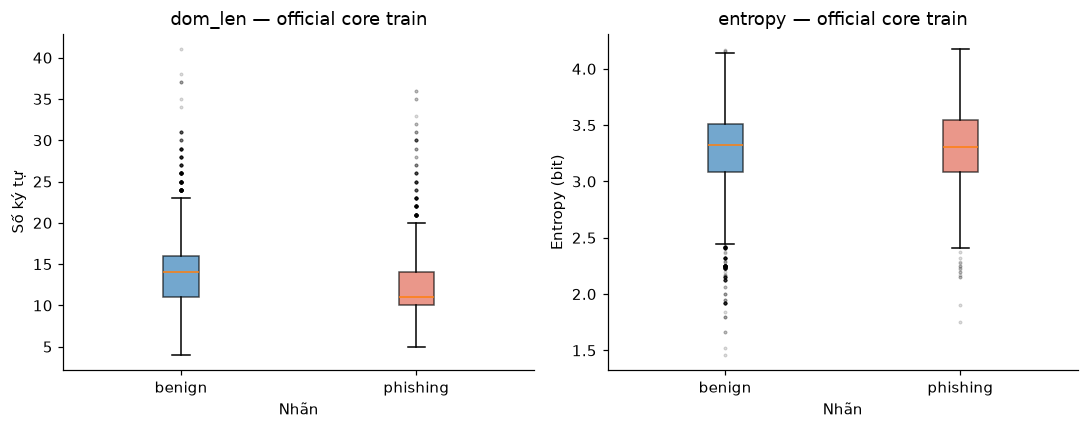

Median dom_len benign/phishing là **14.00/11.00** ký tự; median entropy là **3.324/3.306** bit. Entropy của hai lớp chồng lấn đáng kể trong hình và bảng quantile; khác biệt mô tả này chưa chứng minh sức phân biệt của mô hình hoặc quan hệ nhân quả.

Feature A,Feature B,Spearman ρ
slash_cnt,path_len,1.000
url_len,letter_cnt,0.987
subdom_cnt,dot_cnt,0.898
url_len,dot_cnt,0.751
dom_len,letter_cnt,0.751


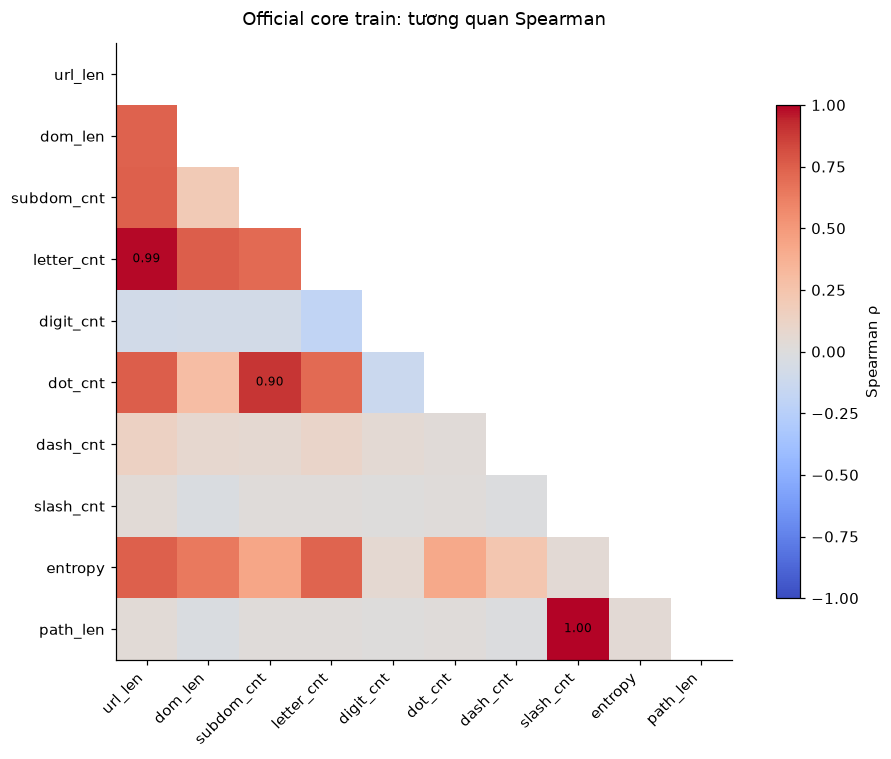

Feature có sẵn,Ngưỡng IQR dưới,Ngưỡng IQR trên,Ngoài ngưỡng (n),Ngoài ngưỡng (%)
url_len,-5.50,38.50,39,0.30%
dom_len,5.00,21.00,441,3.37%
is_ip,0.00,0.00,0,0.00%
subdom_cnt,-1.50,2.50,6,0.05%
letter_cnt,-3.50,32.50,96,0.73%
digit_cnt,0.00,0.00,"1,207",9.23%
dot_cnt,-2.00,6.00,1,0.01%
dash_cnt,0.00,0.00,"1,354",10.35%
under_cnt,0.00,0.00,0,0.00%
slash_cnt,0.00,0.00,34,0.26%


Cột hằng trên official core train: **is_ip, under_cnt**. Cặp tương quan mạnh nhất là **slash_cnt / path_len** (ρ=1.000); các số đếm/độ dài có thể chứa thông tin trùng. slash_cnt/path_len cùng bằng 0 ở **99.74%** mẫu; tương quan gần 1 cần được hiểu cùng mức sparsity này, không suy ra hai công thức hoàn toàn tương đương. Cột hằng chỉ được bỏ khỏi phép tính correlation vốn không xác định, không bị xóa khỏi X. Tương quan cao và IQR=0 ở biến thưa không tự chứng minh feature vô ích hoặc giá trị là lỗi. Không feature selection, cap, scaler hoặc model fitting trong EDA; mọi selector học từ dữ liệu phải ở trong CV fold. So sánh nhãn còn chịu source-label confounding: association không chứng minh khả năng dự đoán ngoài corpus.

In [5]:
feature_train = core_df.loc[core_df["split"].eq("train")].copy()
assert feature_train["split"].eq("train").all()
feature_train_fingerprint = pd.util.hash_pandas_object(feature_train, index=True)
count_candidates = ["url_len", "num_dots", "num_subdomains"]
binary_candidates = ["has_ip", "has_at", "suspicious_tld"]
candidate_checks, available_numeric = [], {}
for feature in count_candidates + binary_candidates:
    if feature not in feature_train:
        candidate_checks.append({"feature": feature, "dtype": "absent", "missing_n": np.nan,
                                 "invalid_n": np.nan, "infinite_n": np.nan, "unique_n": np.nan, "status": "skip: thiếu cột"})
        continue
    values = feature_train[feature]
    numeric = pd.to_numeric(values, errors="coerce")
    invalid = values.notna() & numeric.isna()
    infinite = pd.Series(np.isinf(numeric.to_numpy(dtype=float, na_value=np.nan)), index=values.index)
    invalid |= numeric.lt(0).fillna(False)
    if feature in binary_candidates:
        invalid |= numeric.notna() & ~numeric.isin([0, 1])
    is_numeric = pd.api.types.is_numeric_dtype(values)
    usable = is_numeric and not invalid.any() and not infinite.any() and numeric.notna().any()
    constant = numeric.nunique(dropna=True) <= 1
    status = ("constant; chỉ mô tả" if constant else "có thể mô tả") if usable else "skip: dtype/miền giá trị không hợp lệ"
    candidate_checks.append({
        "feature": feature, "dtype": str(values.dtype), "missing_n": int(values.isna().sum()),
        "invalid_n": int(invalid.sum()), "infinite_n": int(infinite.sum()),
        "unique_n": int(values.nunique(dropna=True)), "status": status,
    })
    if usable:
        available_numeric[feature] = numeric
if "tld" in feature_train:
    candidate_checks.append({
        "feature": "tld", "dtype": str(feature_train["tld"].dtype),
        "missing_n": int(feature_train["tld"].isna().sum()), "invalid_n": np.nan, "infinite_n": np.nan,
        "unique_n": int(feature_train["tld"].nunique()), "status": "categorical; chưa thẩm định công thức parser",
    })
feature_checks = pd.DataFrame(candidate_checks)
table_names.update({
    "feature": "Feature có sẵn", "dtype": "Dtype", "infinite_n": "Inf",
    "missing_n": "Thiếu (n)", "invalid_n": "Không hợp lệ (n)",
    "unique_n": "Giá trị duy nhất", "status": "Trạng thái", "n": "Số quan sát hợp lệ",
    "q25": "Q25", "median": "Median", "q75": "Q75", "q95": "Q95",
    "label": "Nhãn", "zero_n": "Giá trị 0", "one_n": "Giá trị 1", "one_pct": "Giá trị 1 (%)",
    "lower_bound": "Ngưỡng IQR dưới", "upper_bound": "Ngưỡng IQR trên",
    "outlier_n": "Ngoài ngưỡng (n)", "outlier_pct": "Ngoài ngưỡng (%)",
})
# Quantile/correlation là số thực; display_table gốc ưu tiên số đếm nguyên.
# Làm tròn và định dạng bản sao thành chuỗi, không thay giá trị tính toán.
display(Markdown(
    f"Phân tích dưới đây chỉ dùng **{len(feature_train):,} core train URL**, "
    f"trong đó **{int(feature_train['label'].eq('phishing').sum()):,} phishing**. "
    "Bảng kiểm kê phân biệt cột hằng, thiếu dữ liệu và giá trị không hợp lệ; "
    "dtype/miền giá trị hợp lệ chưa đồng nghĩa công thức feature đã được nghiệm thu."
))
display_table(feature_checks, "Bảng 16. Kiểm kê feature candidates trên core train")
quantile_rows, binary_rows, outlier_rows = [], [], []
for feature, values in available_numeric.items():
    if feature in count_candidates:
        for label in labels:
            group = values.loc[feature_train["label"].eq(label)].dropna()
            quantile_rows.append({
                "feature": feature, "label": label, "n": len(group),
                "q25": group.quantile(0.25), "median": group.median(),
                "q75": group.quantile(0.75), "q95": group.quantile(0.95),
            })
        q1, q3 = values.quantile([0.25, 0.75])
        lower, upper = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
        outside = values.lt(lower) | values.gt(upper)
        outlier_rows.append({
            "feature": feature, "lower_bound": lower, "upper_bound": upper,
            "outlier_n": int(outside.sum()), "outlier_pct": 100*outside.sum()/values.notna().sum(),
        })
    else:
        for label in labels:
            group = values.loc[feature_train["label"].eq(label)].dropna()
            binary_rows.append({
                "feature": feature, "label": label, "n": len(group),
                "zero_n": int(group.eq(0).sum()), "one_n": int(group.eq(1).sum()),
                "one_pct": 100*group.eq(1).sum()/len(group) if len(group) else np.nan,
            })
feature_quantiles = pd.DataFrame(quantile_rows)
if not feature_quantiles.empty:
    formatted = feature_quantiles.copy()
    for column in ["q25", "median", "q75", "q95"]:
        formatted[column] = formatted[column].map(lambda x: f"{x:.2f}" if pd.notna(x) else "—")
    display_table(formatted, "Bảng 17. Quantile theo lớp trên core train; n loại missing")
plotted_features = [
    feature for feature in ["url_len", "num_subdomains"]
    if feature in available_numeric and available_numeric[feature].nunique() > 1
]
if plotted_features:
    fig, axes = plt.subplots(1, len(plotted_features), figsize=(5*len(plotted_features), 4), squeeze=False)
    for ax, feature in zip(axes[0], plotted_features):
        samples = [available_numeric[feature].loc[feature_train["label"].eq(label)].dropna() for label in labels]
        boxes = ax.boxplot(samples, patch_artist=True,
                           flierprops={"marker": ".", "alpha": 0.2, "markersize": 3})
        for patch, color in zip(boxes["boxes"], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.65)
        ax.set_xticks([1, 2], labels)
        ax.set(title=f"{feature} — core train", xlabel="Nhãn", ylabel="Giá trị feature có sẵn")
    show_figure(fig)
else:
    display(Markdown("Không đủ cột hợp lệ/biến thiên để vẽ phân bố độ dài hoặc subdomain."))
binary_feature_table = pd.DataFrame(binary_rows)
if not binary_feature_table.empty:
    assert binary_feature_table["zero_n"].add(binary_feature_table["one_n"]).eq(binary_feature_table["n"]).all()
    display_table(binary_feature_table, "Bảng 18. Binary indicators theo lớp; %1 dùng n hợp lệ của lớp")
varying_counts = [f for f in count_candidates if f in available_numeric and available_numeric[f].nunique() > 1]
feature_correlation = pd.DataFrame()
if len(varying_counts) >= 2:
    feature_correlation = pd.DataFrame(available_numeric)[varying_counts].corr(method="spearman")
    formatted = feature_correlation.map(lambda x: f"{x:.3f}" if pd.notna(x) else "—").rename_axis("feature")
    display_table(formatted, "Bảng 19. Tương quan Spearman giữa các count features, train-only")
    display(Markdown(
        "Tương quan mô tả mức đồng biến trong representation có sẵn; không chứng minh nhân quả "
        "hoặc đủ để quyết định loại feature. Nếu có selector học từ dữ liệu, bước đó phải nằm trong từng CV fold."
    ))
outlier_diagnostics = pd.DataFrame(outlier_rows)
if not outlier_diagnostics.empty:
    formatted = outlier_diagnostics.copy()
    for column in ["lower_bound", "upper_bound"]:
        formatted[column] = formatted[column].map(lambda x: f"{x:.2f}")
    display_table(formatted, "Bảng 20. Ngoài [Q1−1.5 IQR, Q3+1.5 IQR] trên core train")
    display(Markdown(
        "Các ngưỡng IQR chỉ dùng mô tả trên train; điểm ngoài ngưỡng vẫn được giữ nguyên "
        "và không được coi mặc định là lỗi hoặc phishing. Whisker của boxplot dùng IQR riêng từng lớp; "
        "bảng 20 dùng IQR gộp toàn core train, nên hai cách đếm điểm ngoài ngưỡng không đồng nhất. "
        "Không cap, winsorize hoặc impute trong EDA."
    ))
if "url_len" in available_numeric:
    length_summary = feature_quantiles.loc[feature_quantiles["feature"].eq("url_len")].set_index("label")
    display(Markdown(
        f"Median url_len của benign/phishing trong core train lần lượt là "
        f"**{length_summary.loc['benign','median']:.2f}/{length_summary.loc['phishing','median']:.2f}**. "
        "Sự khác biệt là association trong corpus, có thể liên quan thành phần nguồn; "
        "chưa cho biết chất lượng dự đoán hoặc feature nào nên được giữ."
    ))
if "has_ip" in available_numeric:
    display(Markdown(
        f"has_ip có **{int(available_numeric['has_ip'].eq(1).sum())}** giá trị 1 "
        f"trên **{int(available_numeric['has_ip'].notna().sum()):,}** core train URL. "
        "Cột hằng trong train không cung cấp bằng chứng về khả năng phát hiện URL dạng IP ngoài dữ liệu này."
    ))
pd.testing.assert_series_equal(
    pd.util.hash_pandas_object(feature_train, index=True), feature_train_fingerprint
)
pd.testing.assert_series_equal(pd.util.hash_pandas_object(original_df, index=True), original_fingerprint)
preliminary_feature_status = "completed" if available_numeric else "pending_valid_candidates"
display(Markdown(
    f"**Trạng thái:** feature EDA sơ bộ core train: {preliminary_feature_status}; "
    "phần official X được bổ sung độc lập ngay dưới; không dùng label val/test cho feature selection."
))

# OFFICIAL FEATURE EDA — representation 12 features của pipeline Hy 65b1054.
dictionary_path = PROJECT_ROOT / "reports/templates/feature_dictionary.csv"
feature_dictionary = pd.read_csv(dictionary_path)
dictionary_source = str(dictionary_path.relative_to(PROJECT_ROOT))
assert not feature_dictionary.empty, "Cần feature dictionary chính thức từ PR #2 đã merge."
official_feature_names = feature_dictionary.loc[feature_dictionary["decision"].eq("keep"), "feature"].tolist()
assert len(official_feature_names) == 12 and len(set(official_feature_names)) == 12
assert "is_https" not in official_feature_names
official_X = pd.read_csv(PROJECT_ROOT / "data/interim/03_matrix_X_features.csv", dtype={"id": "string"})
hy_excluded = pd.read_csv(PROJECT_ROOT / "data/interim/03_excluded_rows.csv", dtype={"id": "string"})
assert list(official_X.columns) == ["id", *official_feature_names]
assert official_X["id"].notna().all() and official_X["id"].is_unique and hy_excluded["id"].is_unique
assert set(official_X["id"]).isdisjoint(hy_excluded["id"])
assert set(official_X["id"]) | set(hy_excluded["id"]) == set(core_df["id"])
assert all(pd.api.types.is_numeric_dtype(official_X[c]) for c in official_feature_names)
assert np.isfinite(official_X[official_feature_names].to_numpy(dtype=float)).all()
metadata_train = core_with_domains.loc[core_with_domains["split"].eq("train"),
    ["id", "label", "source", "tier", "split", "registrable_domain", "error_reason"]]
official_train_X = metadata_train.merge(official_X, on="id", how="inner", validate="one_to_one")
assert official_train_X["split"].eq("train").all()
assert set(metadata_train["id"]) - set(official_train_X["id"]) == set(
    hy_excluded.loc[hy_excluded["id"].isin(metadata_train["id"]), "id"]
)
assert set(eligible_train["id"]).issubset(official_train_X["id"])
official_X_fingerprint = pd.util.hash_pandas_object(official_train_X, index=True)
official_values = official_train_X[official_feature_names]
official_checks = pd.DataFrame({
    "feature": official_feature_names,
    "dtype": [str(official_values[c].dtype) for c in official_feature_names],
    "missing_n": official_values.isna().sum().to_numpy(),
    "infinite_n": np.isinf(official_values.to_numpy(dtype=float)).sum(axis=0),
    "unique_n": official_values.nunique().to_numpy(),
    "nonzero_n": official_values.ne(0).sum().to_numpy(),
})
official_checks["constant"] = official_checks["unique_n"].le(1).map({True: "Có", False: "Không"})
official_checks = official_checks.merge(
    feature_dictionary[["feature", "decision", "formula", "count_scope", "train_check"]],
    on="feature", validate="one_to_one",
)
table_names.update({"constant": "Hằng trên train", "decision": "Dictionary",
                    "nonzero_n": "Khác 0 (n)", "left_feature": "Feature A",
                    "right_feature": "Feature B", "rho": "Spearman ρ"})
display(Markdown(
    f"**Official X của Hy.** Handoff có **{len(official_X):,} URL**, "
    f"**{len(official_feature_names)} numerical features**; phép phân tích liên quan nhãn dưới đây chỉ dùng "
    f"**{len(official_train_X):,} core train URL**. "
    f"Schema/thứ tự được đối chiếu với `{dictionary_source}`, gồm đúng các cột quyết định `keep`. "
    "Các train_check của dictionary còn ghi chưa đo hoặc thống kê toàn official train có bronze; "
    "không đồng nhất chúng với kết quả core train ở đây, và không sửa dictionary của Hy."
))
display_table(official_checks, "Bảng 21. Official X: kiểm tra schema, missing/Inf, sparsity và dictionary",
              ["feature", "dtype", "missing_n", "infinite_n", "unique_n", "nonzero_n", "constant", "decision"])
# Cùng tên cột không bảo đảm cùng công thức giữa representation cũ và official X.
length_comparison = feature_train[["id", "url", "source", "url_len"]].merge(
    official_train_X[["id", "url_len"]], on="id", validate="one_to_one",
    suffixes=("_original", "_official"),
)
length_difference = length_comparison.loc[
    length_comparison["url_len_original"].ne(length_comparison["url_len_official"])
].copy()
raw_length_matches = int(length_difference["url_len_original"].eq(length_difference["url"].str.len()).sum())
display(Markdown(
    f"Trên cùng ID, **{len(length_difference):,}/{len(length_comparison):,}** URL có url_len cũ khác official X. "
    f"Các nguồn liên quan: **{', '.join(sorted(length_difference['source'].unique())) or 'không có'}**; "
    f"**{raw_length_matches:,}** dòng có giá trị cũ bằng độ dài raw URL gồm cả scheme. "
    "Official X bỏ scheme theo dictionary. Vì vậy không đồng nhất các quantile giữa hai representation, "
    "và không sửa dữ liệu gốc hoặc diễn giải chênh lệch này thành lỗi join/loại mẫu."
))
official_quantile_rows, official_outlier_rows = [], []
for feature in official_feature_names:
    values = official_values[feature]
    for label in labels:
        group = official_train_X.loc[official_train_X["label"].eq(label), feature]
        official_quantile_rows.append({
            "feature": feature, "label": label, "n": len(group),
            "q25": group.quantile(0.25), "median": group.median(),
            "q75": group.quantile(0.75), "q95": group.quantile(0.95),
        })
    q1, q3 = values.quantile([0.25, 0.75])
    lower, upper = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
    outside = values.lt(lower) | values.gt(upper)
    official_outlier_rows.append({
        "feature": feature, "lower_bound": lower, "upper_bound": upper,
        "outlier_n": int(outside.sum()), "outlier_pct": 100*outside.mean(),
    })
official_quantiles = pd.DataFrame(official_quantile_rows)
formatted = official_quantiles.copy()
for c in ["q25", "median", "q75", "q95"]:
    formatted[c] = formatted[c].map(lambda v: f"{v:.2f}")
display_table(formatted, "Bảng 22. Official X: quantile theo lớp trên core train")
# Hai phân bố chưa được vẽ trong preliminary EDA: domain length và entropy.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, feature in zip(axes, ["dom_len", "entropy"]):
    samples = [official_train_X.loc[official_train_X["label"].eq(label), feature] for label in labels]
    boxes = ax.boxplot(samples, patch_artist=True, flierprops={"marker": ".", "alpha": 0.2, "markersize": 3})
    for box, color in zip(boxes["boxes"], colors):
        box.set_facecolor(color); box.set_alpha(0.65)
    ax.set_xticks([1, 2], labels)
    ax.set(title=f"{feature} — official core train", xlabel="Nhãn",
           ylabel="Số ký tự" if feature == "dom_len" else "Entropy (bit)")
show_figure(fig)
official_medians = official_quantiles.pivot(index="feature", columns="label", values="median")
display(Markdown(
    f"Median dom_len benign/phishing là **{official_medians.loc['dom_len','benign']:.2f}/"
    f"{official_medians.loc['dom_len','phishing']:.2f}** ký tự; median entropy là "
    f"**{official_medians.loc['entropy','benign']:.3f}/{official_medians.loc['entropy','phishing']:.3f}** bit. "
    "Entropy của hai lớp chồng lấn đáng kể trong hình và bảng quantile; "
    "khác biệt mô tả này chưa chứng minh sức phân biệt của mô hình hoặc quan hệ nhân quả."
))
constant_official = official_checks.loc[official_checks["unique_n"].le(1), "feature"].tolist()
varying_official = [c for c in official_feature_names if c not in constant_official]
official_spearman = official_values[varying_official].corr(method="spearman")
correlated_pairs = pd.DataFrame([
    {"left_feature": a, "right_feature": b, "rho": official_spearman.loc[a, b]}
    for a, b in combinations(varying_official, 2)
]).assign(abs_rho=lambda t: t["rho"].abs()).sort_values("abs_rho", ascending=False)
formatted = correlated_pairs.head(5)[["left_feature", "right_feature", "rho"]].copy()
formatted["rho"] = formatted["rho"].map(lambda v: f"{v:.3f}")
display_table(formatted, "Bảng 23. Năm cặp có |Spearman ρ| lớn nhất; không phải quy tắc loại feature")
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones(official_spearman.shape, dtype=bool))
heatmap = ax.imshow(np.ma.array(official_spearman.to_numpy(), mask=mask),
                    cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(varying_official)), varying_official, rotation=45, ha="right")
ax.set_yticks(range(len(varying_official)), varying_official)
ax.set_title("Official core train: tương quan Spearman", pad=12)
for row in range(len(varying_official)):
    for col in range(row):
        value = official_spearman.iloc[row, col]
        if abs(value) >= 0.8:
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(heatmap, ax=ax, label="Spearman ρ", shrink=0.8)
show_figure(fig)
official_outliers = pd.DataFrame(official_outlier_rows)
formatted = official_outliers.copy()
for c in ["lower_bound", "upper_bound"]:
    formatted[c] = formatted[c].map(lambda v: f"{v:.2f}")
display_table(formatted, "Bảng 24. Official X: outlier diagnostics bằng IQR toàn core train")
top_pair = correlated_pairs.iloc[0]
joint_zero_pct = 100*(official_values["slash_cnt"].eq(0) & official_values["path_len"].eq(0)).mean()
display(Markdown(
    f"Cột hằng trên official core train: **{', '.join(constant_official) or 'không có'}**. "
    f"Cặp tương quan mạnh nhất là **{top_pair['left_feature']} / {top_pair['right_feature']}** "
    f"(ρ={top_pair['rho']:.3f}); các số đếm/độ dài có thể chứa thông tin trùng. "
    f"slash_cnt/path_len cùng bằng 0 ở **{joint_zero_pct:.2f}%** mẫu; tương quan gần 1 "
    "cần được hiểu cùng mức sparsity này, không suy ra hai công thức hoàn toàn tương đương. "
    "Cột hằng chỉ được bỏ khỏi phép tính correlation vốn không xác định, không bị xóa khỏi X. "
    "Tương quan cao và IQR=0 ở biến thưa không tự chứng minh feature vô ích hoặc giá trị là lỗi. "
    "Không feature selection, cap, scaler hoặc model fitting trong EDA; mọi selector học từ dữ liệu phải ở trong CV fold. "
    "So sánh nhãn còn chịu source-label confounding: association không chứng minh khả năng dự đoán ngoài corpus."
))
pd.testing.assert_series_equal(pd.util.hash_pandas_object(official_train_X, index=True), official_X_fingerprint)
pd.testing.assert_series_equal(pd.util.hash_pandas_object(original_df, index=True), original_fingerprint)
official_feature_status = "completed_train_only"


## 5. Kết luận và bàn giao

Dữ liệu gốc gồm **53,116 URL**, với **69.11% phishing**. Core Gold/Silver giữ **18,997 URL (35.77%)**; tỷ lệ phishing còn **13.62%**. Sự thay đổi được giải thích bởi việc loại **34,119** bản ghi bronze, toàn bộ mang nhãn phishing trong corpus hiện tại. Core vì vậy là một quần thể được lựa chọn với cấu trúc lớp và nguồn khác dữ liệu gốc, chưa đủ cơ sở để suy ra generalization tốt hơn.

Trong core, positive chỉ đến từ **tinnhiemmang**, trong khi **7/7 nguồn** của corpus chỉ có một nhãn. Đây là bằng chứng về sự gắn kết giữa nguồn thu thập và nhãn; ảnh hưởng của source-specific artifacts đối với dự đoán vẫn là giả thuyết cần kiểm chứng. Theo datasheet, positive còn bao gồm các loại abuse/fraud ngoài credential phishing, nên phạm vi diễn giải baseline cần phản ánh giới hạn này.

Core validation có **24 phishing trên 1,585 URL** (**1.51%**), còn Gold validation có **0 phishing**. Một positive tương ứng **4.17 điểm phần trăm recall**; do đó validation hiện tại phù hợp cung cấp thông tin bổ sung hơn là làm căn cứ duy nhất cho model selection hoặc threshold tuning. Phúc cần báo cáo số mẫu từng lớp cùng Precision/Recall/F1 phishing, confusion matrix và PR-AUC với định nghĩa rõ ràng; test phải được giữ độc lập với mọi quyết định lựa chọn.

Audit sơ bộ trên dữ liệu gốc và core chưa phát hiện ID, raw URL hoặc `url_norm` giao nhau giữa các split, cũng chưa thấy xung đột nhãn theo hai khóa URL. Đây chỉ là kiểm tra equality của chuỗi; chưa chứng minh độc lập domain hoặc chiến dịch. Temporal diagnostics không ghi nhận ngày có dữ liệu nhưng parse thất bại; trong core, độ bao phủ `collected_at` của phishing/benign lần lượt là **100.00%/12.35%**. Không thay ngày thiếu bằng `scraped_at` hoặc kết luận temporal split sai chỉ từ khoảng ngày giao nhau.

Feature EDA sơ bộ dùng riêng **13,080 core train URL** và các cột có sẵn trong CSV. Median `url_len` benign/phishing là **16.00/13.00**; `has_ip` hằng 0 và tương quan Spearman giữa `num_dots`/`num_subdomains` khoảng **0.899**. Đây là các quan sát của representation PhishVN cũ, không thay thế official X hoặc chứng minh hiệu quả dự đoán. Outlier được mô tả bằng IQR và giữ nguyên; chưa chọn/loại feature, fit preprocessing hay sử dụng nhãn val/test để tối ưu.

Mapping Hy từ commit `65b1054` phủ đủ **18,997 core IDs**. Audit trên **18,995 URL có domain** không phát hiện domain giao nhau ở train/val, train/test hoặc val/test; số URL bị ảnh hưởng ở cả ba cặp là 0. **2 URL unresolved_domain đều thuộc train, nhãn phishing**, được giữ nguyên trong dataset và liệt kê tại bảng 14c, nhưng không đủ điều kiện CV/X. Vì còn domain chưa resolve, không mở rộng kết luận không giao domain sang toàn bộ URL chưa xác định hoặc mọi dạng campaign leakage.

Group CV thật dùng **13,078 URL và 8,835 domain**, 3 fold với seed 42. Kích thước validation folds là **4,359 / 4,359 / 4,360**, số phishing là **691 / 691 / 692**; mỗi fold có cả hai lớp và không giao domain với phần train. Mapping tái lập theo seed, không đổi nhãn hoặc tuning để cải thiện cân bằng. File `data/interim/02_group_folds_train.csv` gồm đúng `id,fold_id`, chỉ chứa official core train đủ điều kiện.

Official feature EDA đối chiếu đủ **12 numerical features** với dictionary cùng commit Hy, chỉ dùng **13,078 core train URL** (benign 11,004, phishing 2,074). Không có NaN/Inf; **is_ip, under_cnt** hằng 0. `slash_cnt/path_len` cùng 0 ở **99.74%** mẫu, nên tương quan gần 1 cần được hiểu cùng sparsity; `url_len/letter_cnt` có ρ≈0.987. Các cột vẫn được giữ nguyên trong X; chưa feature selection, scaler hoặc đánh giá mô hình. IQR diagnostics không tự làm thay đổi dữ liệu.

Trên cùng ID, **1,659 benign core train URL của tinnhiem_org** có `url_len` cũ bao gồm scheme, trong khi official X bỏ scheme theo dictionary. Các số liệu sơ bộ và official vì vậy phải được diễn giải theo đúng representation; không sửa CSV gốc hoặc quy kết khác biệt này thành lỗi join. Source-label confounding vẫn giới hạn khả năng khái quát của các quan sát theo nhãn.

Phần việc Hưng hiện đã chạy trên dữ liệu thật và có artifact bàn giao. Phúc cần nối metadata, X và fold theo ID, dùng đúng thứ tự 12 features, fit các bước học từ dữ liệu trong train của từng fold và giữ official test độc lập với model/feature/threshold selection. Group CV không phải temporal holdout. Hai URL unresolved vẫn cần nhánh xử lý parse ở ứng dụng; việc chốt định nghĩa metric và lựa chọn mô hình thuộc phần baseline, chưa được thực hiện trong EDA.